# [이론] 글로벌 모델 — 지하철 100개 역을 신경망 하나로

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 결정 질문과 가게 예

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">글로벌 모델 — 지하철 100개 역을 신경망 하나로</h1>
<div style="font-size:1.05em;color:#656565">채점 규칙과 신경망을 가게 예로 먼저 보고, 서울 지하철 100개 역의 평가표로 모델을 고릅니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)와 제목에 [선택]이 있는 화면은 선택입니다.

100개 역을 한 모델로 학습한 신경망을 다음 주 역별 인력 예측에 쓸까요?

지금 역 운영팀은 바로 전 7일 승차의 평균을 다음 7일의 예측값으로 써서 역마다 인력을 정합니다. 이 규칙을 **직전 7일 평균**이라 부릅니다.

### 글로벌 MLP 는 어떤 모델인가 [필수]

글로벌 MLP 는 여러 계열의 과거 값으로 학습한 신경망 하나입니다.

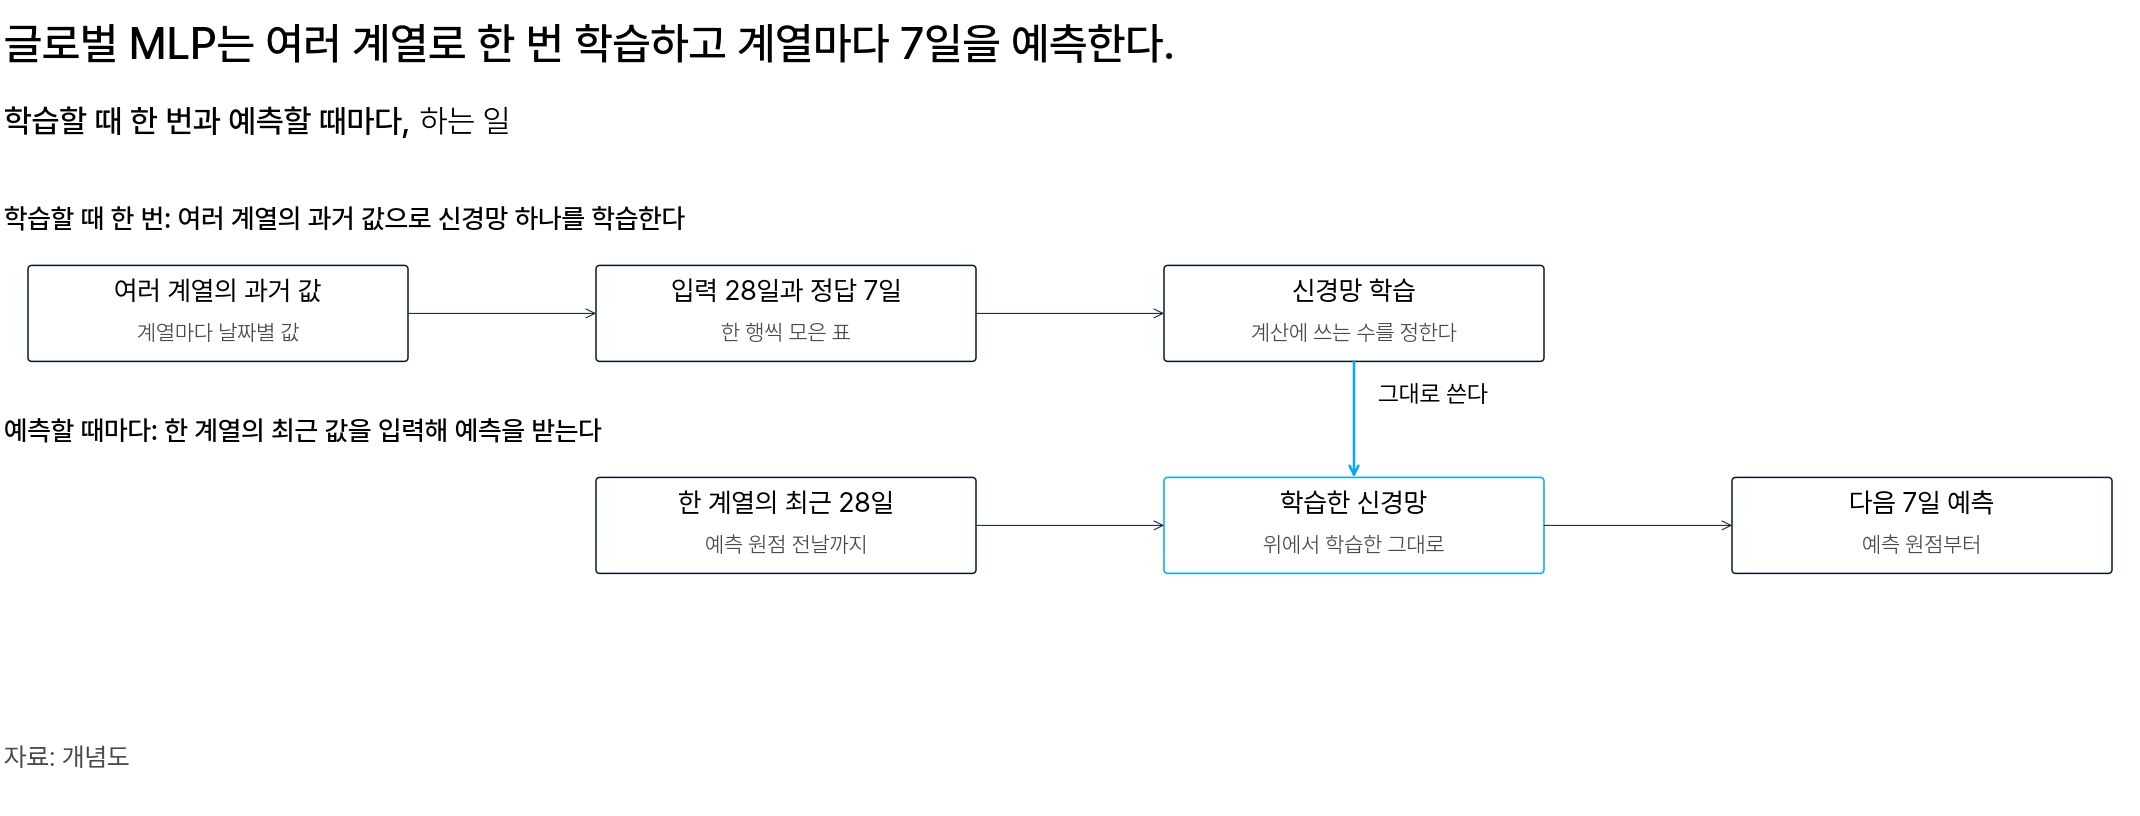

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 위는 학습할 때 한 번 하는 일이고, 아래는 예측할 때마다 하는 일이다. 위에서 학습한 신경망을 아래 계산에 쓴다</em></p>

신경망은 회귀에서 계수를 정하듯, 계산에 쓰는 수를 자료로 정하는 모델입니다. MLP 는 신경망의 한 종류이고, 「4.」에서 정의합니다.

계열은 역 하나의 날짜별 승차처럼, 한 대상의 날짜별 값입니다.

**글로벌 MLP 는 여러 계열로 한 번 학습하고, 계열마다 최근 28일을 입력받아 다음 7일을 예측합니다.**

### 예로 쓸 자료: 가게 하나의 28일 [필수]

모델 설명의 예는 손님 수가 요일마다 되풀이되는 가게 하나입니다.

| 주 | 월 | 화 | 수 | 목 | 금 | 토 | 일 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1주(1～7일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 2주(8～14일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 3주(15～21일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 4주(22～28일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |

계산하기 쉽게 정한 값이고, 단위는 명입니다.

28일의 합은 2,400명이라, 하루 평균은 2,400 ÷ 28 ≈ 85.7명입니다.

그래서 100명인 월～금은 평균보다 높은 날이고, 토·일은 낮은 날입니다.

날은 번호로 부릅니다. 1일째가 1주 월요일이고, 28일째가 4주 일요일입니다.

29일째는 다음 월요일입니다.

**평일은 높고 주말은 낮은 모양이 7일마다 되풀이됩니다.**

<div class="lms-summary">

**정리**

글로벌 MLP 는 여러 계열의 과거 값으로 학습한 신경망 하나이고, 계열마다 다음 7일을 예측합니다.

**할 일**

- 「1.」～「5.」에서는 위 가게 표의 수로 계산하고, 서울 지하철 100개 역의 수는 「6.」부터 나옵니다

이 가게의 날짜별 손님 수가 계열 하나입니다.

</div>

## 1. 예측 원점과 역 단위 MASE

새 모델과 지금 쓰는 직전 7일 평균을 어떤 규칙으로 채점해 비교할까요?

### 예측 원점은 어느 날인가 [필수]

예측하는 7일의 첫날이 예측 원점이고, 예측에는 원점 전날까지의 자료만 씁니다.

가게의 28일째까지 손님 수를 알고, 다음 주 7일을 예측한다고 해 봅니다.

| 날 | 무엇인가 |
|---|---|
| 1～28일째 | 손님 수를 아는 날 |
| 29일째(다음 월요일) | 예측하는 7일의 첫날 |
| 29～35일째 | 예측하고 채점하는 7일 |

29일째가 **예측 원점(forecast origin)** 입니다. 29일째의 손님 수는 그날이 끝나야 알 수 있어, 예측할 때는 없는 값입니다.

시계열 과목의 원점은 학습 구간의 마지막 시각이었고, 이 과정의 원점은 그 하루 뒤입니다.

**원점 전날까지가 입력이고, 원점부터 7일이 채점하는 날입니다.**

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: 원점을 옮겨 가며 채점하는 그림</summary>

<img src="https://otexts.com/fpp3/toolbox_files/figure-html/cv1-1.png" width="640" height="300"/>
<p align="center"><em>▲ 예측 원점을 옮겨 가며 채점하는 시계열 교차 검증(time series cross-validation). 파란 점이 학습에 쓴 관측이고, 주황 점이 채점하는 시각이다 (출처: fpp3 §5.10)</em></p>

시계열 과목에서 본 시계열 교차 검증 그림입니다.

| 그림의 요소 | 뜻 |
|---|---|
| 한 행 | 채점 한 번. 행마다 원점이 다르다 |
| 파란 점 | 학습에 쓴 관측 |
| 주황 점 | 그 행에서 채점하는 시각 |
| 회색 점 | 그 행에서 쓰지 않는 시각 |
| 가로축 time | 시간 |

아래 행일수록 원점이 늦고, 파란 점이 많습니다.

가게의 28일로 옮기면 파란 점이 1～28일째이고, 주황 점은 29일째부터입니다.

그림에서는 행마다 주황 점이 하나지만, 하루만 채점한다는 뜻은 아닙니다.

이 과정에서는 원점부터 이어지는 7일을 채점합니다.

원점이 다섯이라 행도 다섯입니다.

원점을 여럿 두면 휴일이 있는 주와 없는 주를 모두 채점할 수 있습니다.

출처의 fpp3 는 시계열 예측 교재 『Forecasting: Principles and Practice』 3판의 약칭입니다. § 뒤 수는 그 교재의 목차 번호입니다.

</details>

### 직전 7일 평균은 얼마나 빗나가나 [필수]

하루 평균 20.4명 빗나갑니다.

가게의 다음 주 실제 손님 수도 지난 네 주와 같다고 해 봅니다.

예측값은 지난 7일의 합 100 × 5 + 60 + 40 = 600명을 7 로 나눈 85.7명입니다.

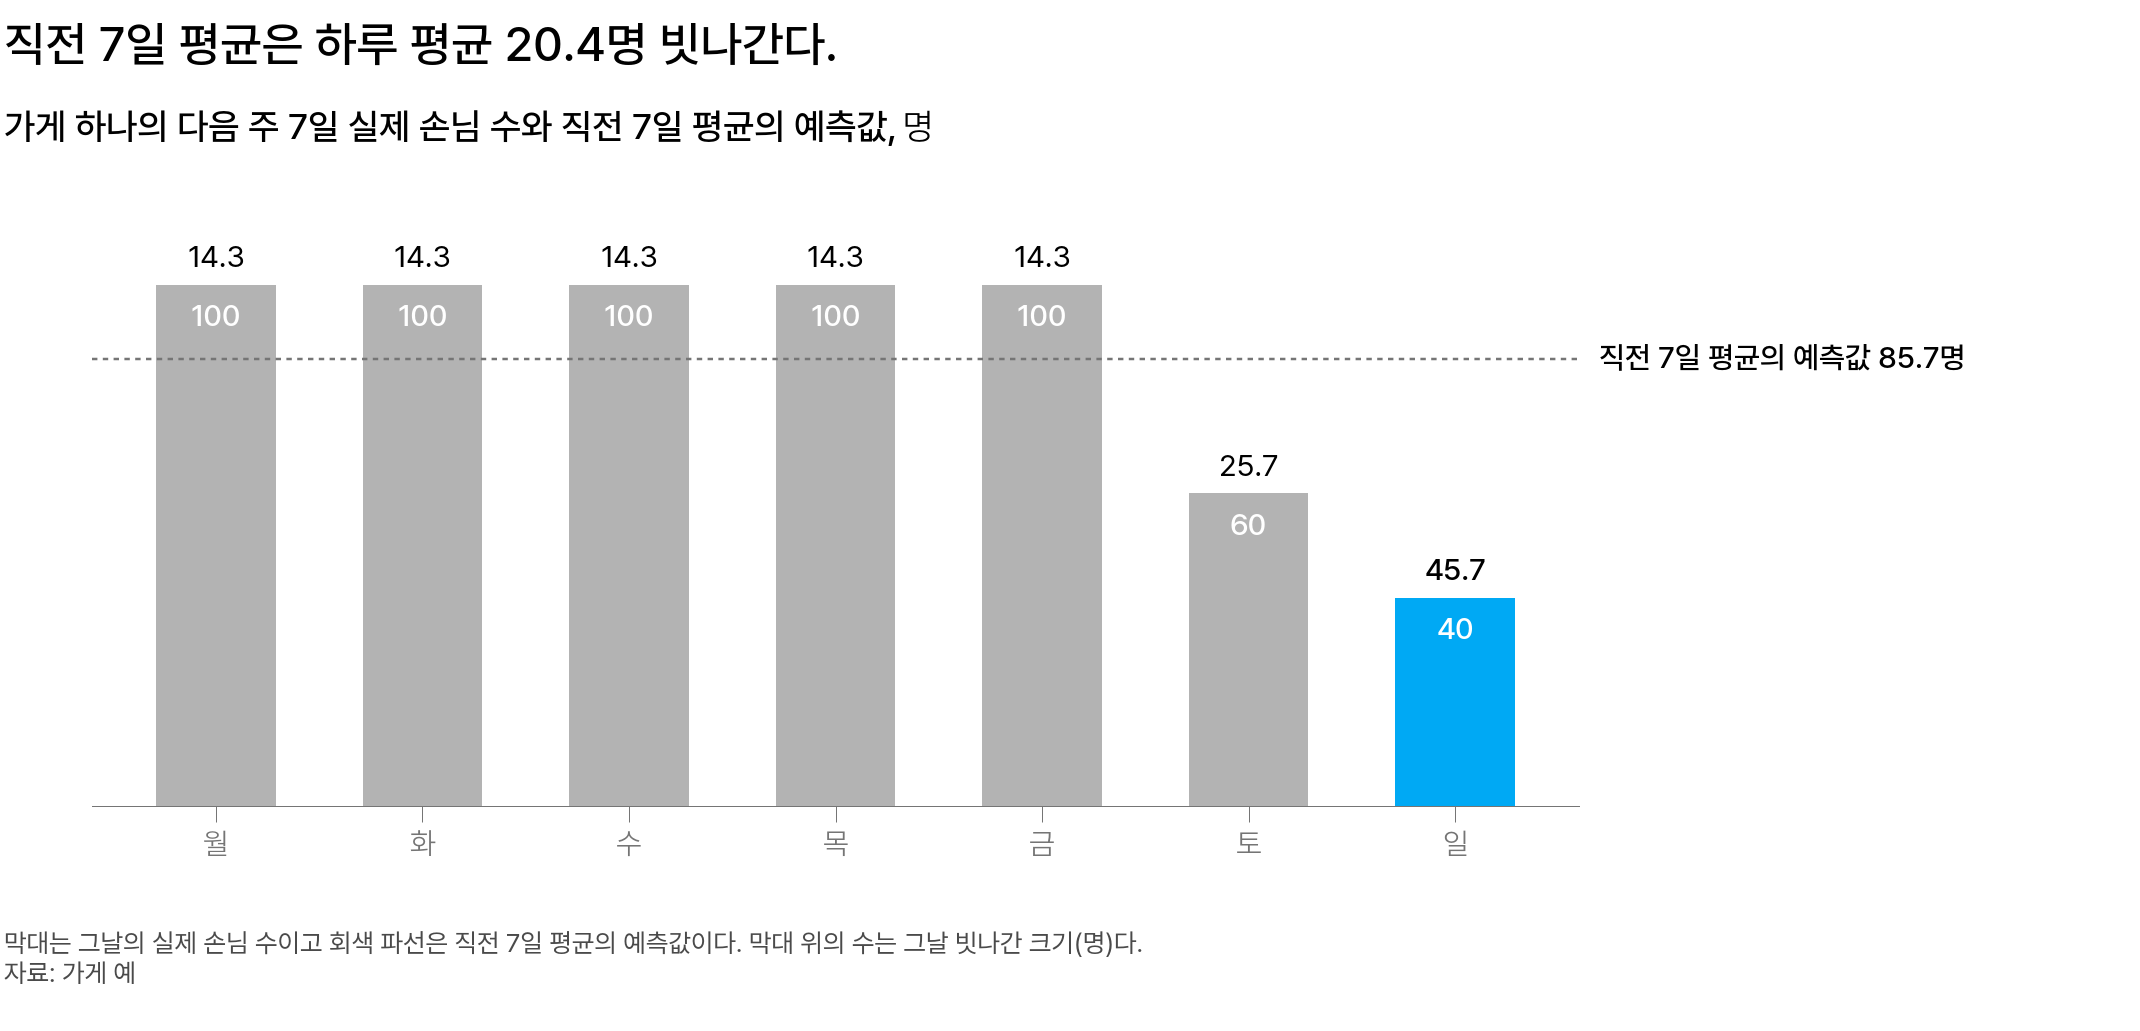

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 다음 주의 요일이고 세로축은 손님 수(명)다. 막대는 실제 손님 수이고, 가로 파선은 직전 7일 평균의 예측값 85.7명이다. 막대 위의 수는 그날 빗나간 크기다</em></p>

예측값과 실제의 차를 부호 없이 적은 값을 **빗나간 크기**라 부릅니다.

평일은 100 − 85.7 = 14.3명, 토 · 일은 85.7 − 60 = 25.7명과 85.7 − 40 = 45.7명입니다.

| 빗나간 크기의 합 | 7일 평균 |
|---|---:|
| 14.3 × 5 + 25.7 + 45.7 = 142.9명 | 142.9 ÷ 7 ≈ 20.4명 |

빗나간 크기를 평균한 값이 **평균 절대 오차(mean absolute error, MAE)** 입니다.

**직전 7일 평균은 평일에는 적게, 주말에는 많게 예측해 하루 평균 20.4명 빗나갑니다.**

### 1주일 전 같은 요일 값을 쓰면 얼마나 빗나가나 [필수]

이 가게에서는 하루도 빗나가지 않습니다.

| 규칙 | 7일의 MAE |
|---|---:|
| 직전 7일 평균 | 20.4명 |
| 1주일 전 같은 요일 값 | 0명 |

둘째 규칙이 **계절 나이브(seasonal naive)** 입니다. 이렇게 학습 없이 과거 값으로 예측값을 정하는 규칙이 **베이스라인(baseline)** 입니다.

네 주가 똑같은 이 가게와 달리, 실제 자료는 날마다 조금씩 달라 계절 나이브도 빗나갑니다.

**새 모델은 학습 없이도 요일 모양을 맞히는 계절 나이브보다 덜 빗나가야 쓸 까닭이 있습니다.**

### 빗나간 크기가 큰지 작은지는 무엇과 비교하나 [필수]

그 계열에서 계절 나이브가 평소 빗나가던 크기와 비교합니다.

하루 20.4명이 큰 오차인지는 가게의 규모에 따라 다릅니다.

20.4명을 계절 나이브가 평소 빗나가던 크기로 나눠 비교합니다.

네 주가 똑같은 이 가게에서는 계절 나이브가 빗나가지 않아 이 크기가 0 이고, 0 으로는 나눌 수 없습니다.

그래서 가게의 값을 하루만 바꿉니다. 2주 수요일(10일째)이 휴일이라 손님이 20명이었다고 해 봅니다.

| 주 | 월 | 화 | 수 | 목 | 금 | 토 | 일 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 2주(8～14일째) | 100 | 100 | 20 | 100 | 100 | 60 | 40 |

**빗나간 크기는 계절 나이브가 평소 빗나가던 크기로 나눠 비교합니다.**

### 계절 나이브가 평소 빗나가던 크기는 어떻게 구하나 [필수]

원점 전날까지 계절 나이브가 빗나간 크기를 평균합니다.

1～7일째는 1주일 전 값이 없어, 8～28일째의 21일만 평균합니다.

| 날 | 계절 나이브의 예측값(1주일 전 값) | 실제 | 빗나간 크기 |
|---|---:|---:|---:|
| 10일째(2주 수요일, 휴일) | 100명 | 20명 | 80명 |
| 17일째(3주 수요일) | 20명 | 100명 | 80명 |
| 나머지 19일 | 실제와 같음 | | 0명 |

21일의 평균은 (80 + 80) ÷ 21 ≈ 7.6명입니다.

20.4명을 나눌 이 평균을 **MASE 분모** $Q$ 라 부릅니다.

**이 가게에서 계절 나이브는 원점 전날까지 하루 평균 7.6명 빗나갔습니다.**

### MASE 는 어떻게 계산하고 읽나 [필수]

모델이 빗나간 크기를 MASE 분모로 나눈 값이 MASE 입니다.

$$
\text{MASE} = \frac{\text{MAE}}{Q}
$$

- $\text{MAE}$: 채점하는 7일에 모델이 빗나간 크기의 평균
- $Q$: 원점 전날까지 계절 나이브가 빗나간 크기의 평균

**평균 절대 스케일 오차(mean absolute scaled error, MASE)** 는 시계열 과목에서 배운 지표입니다.

값을 바꾼 날은 2주 수요일뿐이라, 원점 전 7일과 다음 주의 값은 그대로입니다.

직전 7일 평균이 빗나간 크기도 20.4명 그대로입니다.

그래서 직전 7일 평균의 MASE 는 20.4 ÷ 7.6 ≈ 2.7 입니다.

| MASE 값 | 뜻 |
|---|---|
| 1 | 계절 나이브가 원점 전날까지 평소 빗나가던 만큼 빗나감 |
| 1 보다 작음 | 평소보다 덜 빗나감 |
| 1 보다 큼 | 평소보다 더 빗나감 |

**MASE 는 그 계열에서 계절 나이브가 평소 빗나가던 크기의 몇 배를 빗나갔는지를 나타냅니다.**

<details class="lms-extra"><summary>자세히 — 계절 나이브와 MAE · Q 를 식으로 적으면</summary>

계절 나이브의 예측값은 1주일 전 같은 요일의 실제 값입니다.

$$
\hat y_{o+h} = y_{o+h-7}
$$

- $o$: 예측 원점
- $h$: 원점에서 며칠 뒤인지(0～6)
- $\hat y_{o+h}$: 원점 $h$일 뒤의 예측값
- $y_{o+h-7}$: 1주일 전 같은 요일의 실제 값

$h = 6$ 이어도 원점 전날 값 $y_{o-1}$ 까지만 씁니다.

7 은 주기 $m$ 입니다. 서울 공유자전거는 시간 단위라 $m = 24$ 였고, 서울 지하철은 하루 단위라 $m = 7$ 입니다.

계열이 여럿이면 식에 계열 번호 $i$ 를 적습니다. 분자는 채점하는 7일에 모델이 계열 $i$ 에서 빗나간 크기의 평균입니다.

$$
\text{MAE}_i = \frac{1}{7}\sum_{h=0}^{6} |y_{i,o+h} - \hat y_{i,o+h}|
$$

- $y_{i,o+h}$: 계열 $i$ 의 원점 $h$일 뒤 실제 값
- $\hat y_{i,o+h}$: 같은 날 모델의 예측값

분모는 원점 전날까지 계절 나이브가 계열 $i$ 에서 빗나간 크기의 평균입니다.

$$
Q_i = \frac{1}{n}\sum_{t} |y_{i,t} - y_{i,t-7}|
$$

- $t$: 1주일 전 값이 있는 날부터 원점 전날까지의 날
- $n$: 그런 날의 수
- $|y_{i,t} - y_{i,t-7}|$: 그날 계절 나이브가 빗나간 크기

2주 수요일이 휴일인 가게에서는 $t$ 가 8～28일째라 $n = 21$ 입니다.

</details>

### 같은 4명 오차는 두 가게에서 같은 크기인가 [필수]

같지 않습니다. 가게 A 에서는 평소의 절반이고, 작은 가게 B 에서는 평소의 2배입니다.

지금까지의 가게를 가게 A 라 부르고, 평일 손님이 30명인 작은 가게 B 도 예로 듭니다.

가게 B 도 2주 수요일이 휴일이었고, 그날 손님은 9명이었다고 해 봅니다.

| 가게 | 휴일 때문에 빗나간 크기 | MASE 분모 $Q$ | 하루 4명 빗나갈 때의 MASE |
|---|---:|---:|---:|
| 가게 A | 100 − 20 = 80명씩 이틀 | (80 + 80) ÷ 21 ≈ 7.6명 | 4 ÷ 7.6 ≈ 0.5 |
| 가게 B | 30 − 9 = 21명씩 이틀 | (21 + 21) ÷ 21 = 2명 | 4 ÷ 2 = 2 |

**같은 4명도 그 가게에서 평소 빗나가던 크기와 비교해야 큰지 작은지 알 수 있습니다.**

### 계열이 여럿이면 MASE 를 어떻게 모으나 [필수]

계열마다 MASE 를 구한 뒤 평균합니다.

앞의 두 가게라면 (0.5 + 2) ÷ 2 = 1.25 입니다.

$$
\text{계열마다 구한 MASE 의 평균} = \frac{1}{N}\sum_{i=1}^{N} \frac{\text{MAE}_i}{Q_i}
$$

- $N$: 계열 수. 두 가게에서는 2
- $i$: 계열 번호(1～$N$)
- $\text{MAE}_i$, $Q_i$: 계열 $i$ 의 MAE 와 MASE 분모

서울 지하철에서는 계열이 역이라, 이 값을 **역 단위 MASE** 라 부릅니다.

인력은 가게나 역마다 따로 두므로 오차도 계열마다 구합니다. 계열을 더해 채점하면, 많게 예측한 곳과 적게 예측한 곳의 오차가 서로 지워집니다.

**오차와 MASE 분모는 계열을 더하지 않고 계열마다 구합니다.**

### 역 단위 MASE 의 좋은 점과 약한 점 [선택]

규모가 다른 계열을 함께 비교할 수 있지만, 몇 명 빗나갔는지는 바로 알 수 없습니다.

- **좋은 점**: 규모가 다른 계열의 오차를 같은 기준으로 비교합니다
- **약한 점**: 몇 명 빗나갔는지는 $Q_i$ 를 곱해야 알 수 있습니다
- **이럴 때 쓴다**: 규모가 다른 계열을 모아 모델끼리 비교할 때입니다

계열을 더해 채점하면 안 되는 까닭은 수로 확인합니다. 어느 평일에 가게 A 를 10명 많게, 가게 B 를 10명 적게 예측했다고 해 봅니다.

| 채점하는 대상 | 실제 | 예측값 | 오차 |
|---|---:|---:|---:|
| 가게 A | 100명 | 110명 | 10명 많음 |
| 가게 B | 30명 | 20명 | 10명 적음 |
| 두 가게를 더한 값 | 130명 | 130명 | 0명 |

더한 값으로 채점하면 오차가 0명입니다. 그래도 가게 A 는 인력이 남고 가게 B 는 모자랍니다.

**오차를 가게마다 구해야, 많게 예측한 오차와 적게 예측한 오차가 지워지지 않습니다.**

### 채점하는 주에 휴일이 있으면 MASE 는 어떻게 달라지나 [필수]

이 가게의 계절 나이브는 휴일이 있는 주에 MASE 가 1.5 로, 1 을 넘습니다.

2주 수요일이 휴일인 가게 A 에서, 다음 주를 두 경우로 나눠 봅니다.

| 다음 주 | 계절 나이브가 빗나간 날 | 하루 평균 | MASE |
|---|---|---:|---:|
| 휴일이 없는 경우 | 없음 | 0명 | 0 |
| 수요일(31일째)이 휴일이라 20명인 경우 | 수요일 하루 80명 | 80 ÷ 7 ≈ 11.4명 | 11.4 ÷ 7.6 = 1.5 |

채점하는 주에 계절 나이브가 빗나가는 크기는 평소 크기 $Q$ 와 다를 수 있어, 계절 나이브의 MASE 도 1 이 아닐 수 있습니다.

**새 모델의 MASE 는 1 이 아니라 같은 주의 계절 나이브 MASE 와 비교합니다.**

### 채점하는 주는 어떻게 나눠 평균하나 [필수]

휴일이 있는 주와 없는 주로 나눠 평균합니다.

| 평균하는 방법 | 계절 나이브의 MASE |
|---|---:|
| 휴일이 없는 경우만 | 0 |
| 휴일이 있는 경우만 | 1.5 |
| 두 경우를 한꺼번에 | (0 + 1.5) ÷ 2 = 0.75 |

한꺼번에 평균한 0.75 는 어느 경우의 MASE 도 아닙니다.

서울 지하철에서는 공휴일이면서 월～금인 날을 **평일 공휴일**이라 부릅니다. 채점 7일의 월～금에 공휴일이 하루라도 있으면 공휴일 있는 주입니다.

대부분의 주에는 평일 공휴일이 없으므로, 새 모델을 쓰려면 먼저 공휴일 없는 주에서 계절 나이브보다 MASE 가 낮아야 합니다.

**공휴일 있는 주와 없는 주로 나눠 평균하고, 공휴일 없는 주의 값을 먼저 확인합니다.**

<div class="lms-summary">

**정리**

역 단위 MASE 는 역마다 모델의 MAE 를 그 역의 $Q_i$ 로 나눠 평균한 값입니다. 채점하는 주는 공휴일 있는 주와 없는 주로 나눠 평균합니다.

**할 일**

- $Q_i$ 는 원점 전날까지의 자료로만 구합니다. 실습 코드에서는 `qden` 이라 부릅니다

새 모델을 쓰려면 먼저 공휴일 없는 주에서 계절 나이브보다 MASE 가 낮아야 합니다.

</div>

## 2. 윈도 표

계열 하나를 신경망이 입력받는 표로 어떻게 바꿀까요?

### 윈도 한 행은 무엇인가 [필수]

연속한 며칠을 입력으로, 그 뒤 며칠을 정답으로 묶은 한 행이 윈도입니다.

가게의 4주(22～28일째)를 입력 3일 · 출력 2일로 잘라 봅니다.

| 윈도 | 입력 3일 | 출력 2일(정답) |
|---|---|---|
| 윈도 1 | 100 · 100 · 100 (월～수) | 100 · 100 (목·금) |
| 윈도 2 | 100 · 100 · 100 (화～목) | 100 · 60 (금·토) |
| 윈도 3 | 100 · 100 · 100 (수～금) | 60 · 40 (토·일) |

표의 한 행이 **윈도(window)** 이고, 윈도를 모은 표가 **윈도 표**입니다.

신경망은 입력 열과 정답 열로 된 이 표로 학습합니다. 지도학습에서 쓰는 표와 같은 모양입니다.

윈도는 하루씩 옮겨 자릅니다. 그래서 금요일 값은 윈도 1 에서는 정답이고 윈도 3 에서는 입력입니다.

<img src="https://skforecast.org/0.14.0/img/transform_timeseries.gif" width="640" height="164"/>
<p align="center"><em>▲ 길이 10 인 계열을 입력 5개 · 정답 1개 윈도로 하루씩 옮겨 자르는 과정. 검은 테두리가 입력이고 빨간 테두리가 정답이다 (출처: skforecast)</em></p>

**윈도 한 행은 연속한 입력과 그 뒤의 정답이고, 하루씩 옮겨 자릅니다.**

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: 길이 10 계열을 윈도로 자르는 과정</summary>

위 그림은 길이 10 인 계열을 입력 5개 · 정답 1개 윈도로 자르는 과정입니다.

| 그림에서 | 뜻 |
|---|---|
| 왼쪽에 가로로 적힌 1～10 | 계열 하나. 수 하나가 하루 값이다 |
| 검은 테두리의 수 다섯 | 윈도 하나의 입력 |
| 빨간 테두리의 수 하나 | 그 윈도의 정답 |
| 가운데 표의 한 행 | 윈도 하나의 입력 5개 |
| 오른쪽에 세로로 적힌 빨간 수 | 같은 행의 정답 |

왼쪽의 테두리는 한 번에 하루씩 오른쪽으로 옮겨 갑니다.

옮길 때마다 가운데 표와 오른쪽 정답에 한 행이 더해집니다.

첫 행은 입력 1 · 2 · 3 · 4 · 5 에 정답 6 입니다.

둘째 행은 입력 2 · 3 · 4 · 5 · 6 에 정답 7 입니다.

마지막 행은 입력 5 · 6 · 7 · 8 · 9 에 정답 10 이라, 가운데 표는 5행입니다.

윈도끼리 날이 겹치면 안 된다고 생각하기 쉽지만, 겹쳐도 됩니다.

하루씩 옮겨 자르므로 이웃한 두 윈도는 입력 다섯 가운데 넷이 같습니다.

이 과정의 MLP 에 쓰는 윈도도 같은 방법으로 자르고, 길이만 입력 28일 · 출력 7일로 다릅니다.

</details>

### 입력은 며칠이어야 하나 [선택]

> **[예측] 위 윈도 셋의 입력은 모두 100 · 100 · 100 입니다. 이 입력만으로 다음 이틀을 정할 수 있을까요?**
>
> 1. 100 · 100 으로 정한다
> 2. 60 · 40 으로 정한다
> 3. 정할 수 없다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

정할 수 없습니다. 입력이 같은데 정답은 셋 다 다릅니다.

입력이 같으면 모델의 예측도 같습니다. 그래서 세 윈도 가운데 하나만 맞힐 수 있습니다.

입력을 7일로 늘리면 세 윈도의 입력이 서로 달라집니다.

| 입력 7일 | 출력 2일(정답) |
|---|---|
| 100 · 100 · 60 · 40 · 100 · 100 · 100 (목～수) | 100 · 100 (목·금) |
| 100 · 60 · 40 · 100 · 100 · 100 · 100 (금～목) | 100 · 60 (금·토) |
| 60 · 40 · 100 · 100 · 100 · 100 · 100 (토～금) | 60 · 40 (토·일) |

입력 7일에서는 낮은 값 60 · 40 의 위치가 윈도마다 달라, 다음 이틀이 무슨 요일인지 정해집니다.

이 과정의 입력 28일은 4주라, 계절 나이브가 쓰는 1주일 전 값도 그 안에 있습니다.

**입력 길이는 되풀이되는 주기인 7일 이상으로 둡니다.**

### 윈도는 몇 개가 나오나 [선택]

구간의 길이에서 입력과 출력의 길이를 빼고 1 을 더한 만큼 나옵니다.

$$
\text{윈도 개수} = T - L - H + 1
$$

- $T$: 자를 구간의 길이
- $L$: 입력 길이
- $H$: 출력 길이

| 자르는 구간 | $T$ | $L$ | $H$ | 윈도 개수 |
|---|---:|---:|---:|---:|
| 가게의 4주(22～28일째) | 7 | 3 | 2 | 7 − 3 − 2 + 1 = 3개 |
| 움직이는 그림의 계열 | 10 | 5 | 1 | 10 − 5 − 1 + 1 = 5개 |

「윈도 한 행은 무엇인가」의 표가 3행이고 움직이는 그림의 가운데 표가 5행이라, 식의 답과 같습니다.

**길이 $T$ 인 구간을 하루씩 옮겨 자르면 윈도는 $T - L - H + 1$ 개입니다.**

### 예측 원점에서는 어느 윈도를 쓰나 [필수]

출력 첫날이 원점인 윈도를 쓰고, 입력은 원점 전날에서 끝납니다.

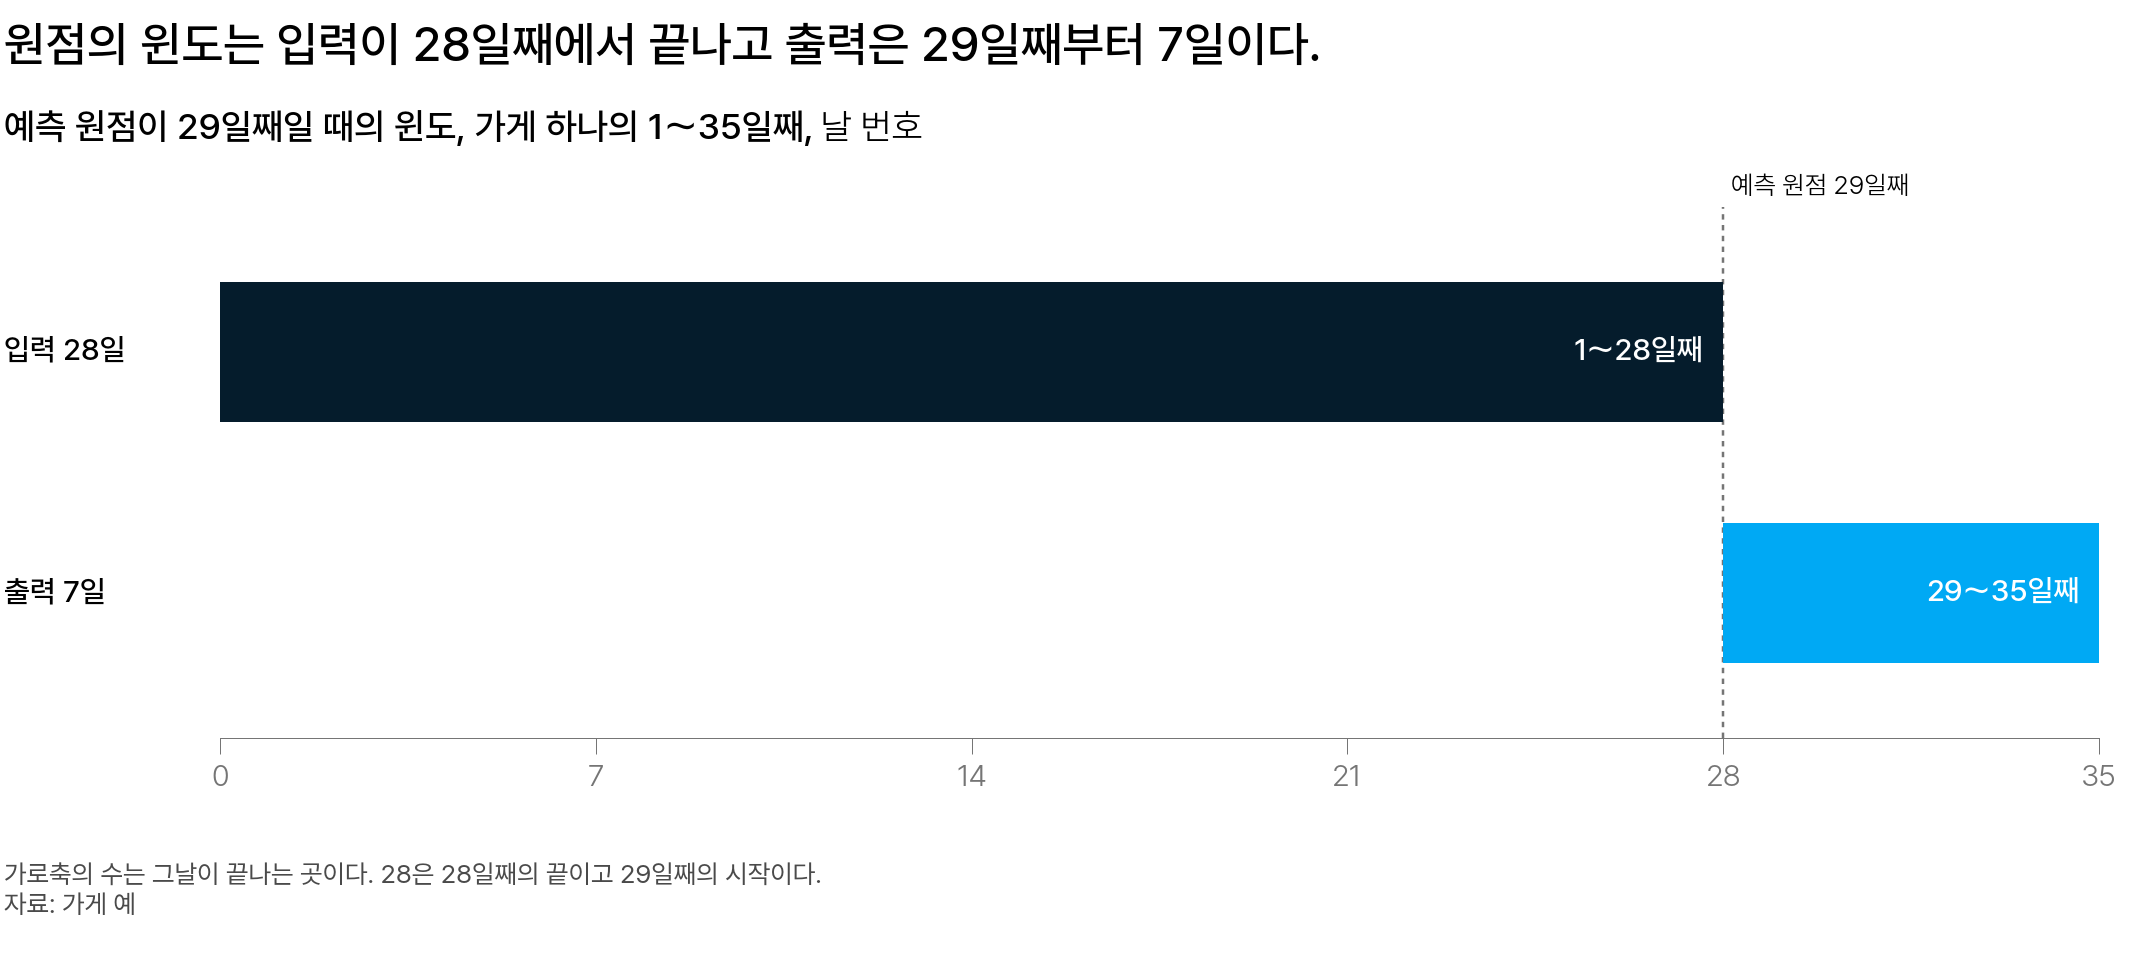

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 가게의 날 번호다. 남색이 입력 28일(1～28일째)이고 하늘색이 출력 7일(29～35일째)이다. 세로 파선이 예측 원점인 29일째다</em></p>

앞에서 쓴 입력 3일 · 출력 2일은 표를 작게 보이려고 줄인 길이입니다. 이 과정의 MLP 는 입력 28일로 그 뒤 7일을 예측합니다.

가게 자료는 28일뿐이라, 입력 28일 뒤에 정답으로 쓸 날이 없습니다.

학습에 쓰는 윈도는 자료가 더 길 때, 정답 7일까지 아는 과거의 날에서 자릅니다.

원점의 윈도에는 입력만 있습니다.

원점 당일의 값은 채점 첫날의 정답입니다. 이 값을 입력에 포함하면 정답이 입력에 있게 되고, 이것이 **데이터 누수(data leakage)** 입니다.

**원점의 윈도는 입력이 원점 전날에서 끝나고, 원점 당일 값은 입력에 포함하지 않습니다.**

### 7일을 한 번에 내나, 하루씩 내나 [필수]

이 과정의 MLP 는 출력 7개로 7일을 한 번에 냅니다. 이 방식이 **다중 출력 방식(multi-output)** 입니다.

방금 낸 예측값을 다음 날 예측의 입력으로 다시 쓰는 방식은 **재귀 다단계 예측**입니다.

| 방식 | 7일을 내는 방법 | 예측값을 입력으로 다시 쓰나 |
|---|---|---|
| 다중 출력 방식 | 출력 7개를 한 번에 냄 | 쓰지 않음 |
| 재귀 다단계 예측 | 하루씩 내고, 낸 값을 다음 날의 입력으로 씀 | 씀 |

**다중 출력 방식은 예측값을 입력으로 다시 쓰지 않아, 앞날의 오차가 다음 날 입력으로 옮겨 가지 않습니다.**

### 재귀 다단계 예측은 어떤 차례로 계산하나 [선택]

하루를 예측한 뒤, 그 예측값을 입력으로 써서 다음 날을 예측합니다.

<img src="https://skforecast.org/0.14.0/img/diagram-recursive-mutistep-forecasting.png" width="640" height="314"/>
<p align="center"><em>▲ 하루 뒤만 예측하는 모델로 사흘을 예측하는 차례. 파란 상자는 관측값이고 주황 상자는 예측값이다. 둘째 행부터는 방금 낸 예측값이 입력에 있다 (출처: skforecast)</em></p>

29일째의 예측값을 30일째 예측의 입력으로 쓰는 식이고, 시계열 과목의 SARIMA 가 이 방식입니다.

그림에서 입력 넷 가운데 예측값은 행마다 0개, 1개, 2개로 늘어납니다.

앞날 예측이 빗나가면, 그 빗나간 값이 다음 날의 입력이 됩니다.

**재귀 다단계 예측은 뒤의 날을 예측할수록 입력에 예측값이 많아집니다.**

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: 재귀 다단계 예측</summary>

위 그림은 이 과정의 MLP 가 쓰지 않는 재귀 다단계 예측의 차례입니다.

| 그림의 말 | 뜻 |
|---|---|
| T-1, …, T-n | 예측하는 때보다 1일 전, …, n일 전의 값 |
| T+1 · T+2 · T+3 | 1일 뒤 · 2일 뒤 · 3일 뒤의 값 |
| Observed value | 관측값. 파란 상자다 |
| Predicted value | 예측값. 주황 상자다 |
| Predictors (lags) | 모델의 입력. 빨간 점선 안의 상자 넷이다 |
| Model trained to predict step +1 | 하루 뒤만 예측하도록 학습한 모델 |

그림은 위에서 아래로 읽습니다.

첫 행은 T-4～T-1 의 관측값 넷으로 T+1 을 예측합니다.

둘째 행은 T-3～T-1 의 관측값 셋과 방금 예측한 T+1 로 T+2 를 예측합니다.

셋째 행은 관측값 둘과 예측값 둘로 T+3 을 예측합니다.

예측값을 다시 입력하면 늘 더 빗나간다고 생각하기 쉽지만, 그림만으로는 알 수 없습니다.

그림에서 알 수 있는 것은 앞날의 오차가 다음 날 입력으로 옮겨 간다는 데까지입니다.

시계열 과목의 SARIMA 는 이 그림처럼 하루씩 예측합니다.

이 과정의 MLP 는 한 번 계산해 7일의 값 7개를 냅니다.

</details>

<div class="lms-summary">

**정리**

계열은 입력 28일 → 출력 7일 윈도로 자르고, 예측 원점에서는 입력이 원점 전날에서 끝나는 윈도를 씁니다.

**할 일**

- 원점마다 입력 윈도의 끝날이 원점 전날인지 출력해 확인합니다

출력 7개로 7일을 한 번에 냅니다.

</div>

## 3. 글로벌 모델과 계열별 표준화

여러 계열을 모델 하나로 모을 때 무엇을 맞춰야 할까요?

### 로컬 모델과 글로벌 모델은 무엇이 다른가 [필수]

로컬 모델은 가게마다 하나이고, 글로벌 모델은 모든 가게에 하나입니다.

휴일이 없던 처음 표로 돌아가, 가게 A 와 작은 가게 B 를 함께 적습니다.

| 가게 | 월～금 | 토 | 일 | 하루 평균 |
|---|---:|---:|---:|---:|
| 가게 A | 100 | 60 | 40 | 600 ÷ 7 ≈ 85.7명 |
| 가게 B | 30 | 20 | 10 | 180 ÷ 7 ≈ 25.7명 |

가게마다 그 가게의 윈도로 모델을 하나씩 학습하면 **로컬 모델(local model)** 입니다. 여러 가게의 윈도를 한 표로 모아 모델 하나를 학습하면 **글로벌 모델(global model)** 입니다.

두 가게는 규모가 달라도 요일 모양이 같아, 윈도를 한 표로 모으면 같은 요일 모양을 두 배 많은 윈도로 학습합니다.

<img src="https://skforecast.org/0.14.0/img/forecaster_multi_series_train_matrix_diagram.png" width="640" height="245"/>
<p align="center"><em>▲ 계열 둘을 학습 표 하나로 모으는 차례. 계열마다 따로 입력과 정답을 만든 뒤 세로로 합친다. 그림의 exog 열(값과 함께 입력하는 다른 열)과 series 1 · series 2 열은 이 과정의 MLP 에 입력하지 않는다 (출처: skforecast)</em></p>

윈도는 가게마다 따로 자른 뒤 한 표로 합쳐, 윈도 한 행에는 한 가게의 값만 있습니다.

모델이 하나여도 가게마다 그 가게의 과거를 입력하므로, 예측은 가게마다 다릅니다.

**글로벌 모델은 계열마다 따로 자른 윈도를 한 표로 모아 모델 하나를 학습합니다.**

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: 두 계열을 학습 표 하나로 모으는 그림</summary>

위 그림은 skforecast 문서의 그림이고, 글로벌 모델의 학습 표를 만드는 차례입니다.

| 그림의 말 | 뜻 | 이 과정의 MLP |
|---|---|---|
| Series 1 · Series 2 | 계열 둘. 가게 예로는 가게 A 와 가게 B | 계열 100개 |
| Exogenous variable · exog | 값과 함께 입력하는 다른 열 | 입력하지 않는다 |
| value · id serie | 가운데 표의 값 열과 계열 이름 열 | 같다 |
| lag 3 · lag 2 · lag 1 | 3일 전 · 2일 전 · 1일 전 값. 입력이다 | 28일 전～1일 전 값 |
| series 1 · series 2 (0 과 1) | 어느 계열의 행인지 알리는 열 | 입력하지 않는다 |
| Y | 정답 | 뒤 7일의 값 |
| Training Matrix | 학습 표. 윈도 표와 같은 말이다 | 같다 |

그림은 왼쪽에서 오른쪽으로 읽습니다.

왼쪽은 길이 7 인 계열 둘이고, 가운데는 두 계열을 세로로 합친 표입니다.

오른쪽은 계열마다 따로 입력 셋과 정답 하나를 만든 뒤 세로로 합친 학습 표입니다.

길이 7 · 입력 3 · 출력 1 이면 계열마다 7 − 3 − 1 + 1 = 4행입니다.

두 계열을 합친 학습 표는 8행입니다.

한 표로 모으면 두 계열의 값이 한 행에 함께 있다고 생각하기 쉽지만, 그렇지 않습니다.

주황 계열의 첫 행은 101 · 102 · 103 이고, 이 행에 파란 계열의 값은 없습니다.

이 과정의 MLP 에 쓰는 학습 표도 계열마다 따로 자른 뒤 합쳐 만들고, 윈도는 입력 28일 · 출력 7일입니다.

</details>

### 로컬 모델과 글로벌 모델은 언제 쓰나 [선택]

계열이 많고 요일 모양이 비슷하면 글로벌 모델을 씁니다.

| 구분 | 로컬 모델 | 글로벌 모델 |
|---|---|---|
| 모델 개수 | 가게마다 하나 | 모든 가게에 하나 |
| 학습에 쓰는 윈도 | 28 − 7 − 7 + 1 = 15개 | 두 가게의 30개 |
| 예측할 때의 입력 | 그 가게의 과거 값 | 그 가게의 과거 값 |

가게 자료가 28일뿐이라 윈도는 입력 7일 · 출력 7일로 잘랐습니다.

가게 A 를 예측할 때 가게 B 의 값은 입력하지 않습니다. 가게 B 의 윈도는 모델을 학습할 때만 쓰입니다.

고르는 기준은 이렇습니다.

- **계열이 많고 요일 모양이 비슷하다 → 글로벌 모델**
- **계열이 몇 개뿐이고 계열마다 자료가 길다 → 로컬 모델도 후보**

요일 모양이 달라도 글로벌 모델을 쓸 수 있습니다. 입력이 계열마다 달라, 같은 모델이 다른 예측을 내기 때문입니다.

어느 쪽이 덜 빗나가는지는 같은 원점과 같은 지표로 둘 다 채점해야 알 수 있습니다.

**글로벌 모델은 같은 요일 모양을 더 많은 윈도로 학습하고, 입력은 계열마다 따로 받습니다.**

### 문 연 지 14일인 가게도 예측할 수 있나 [선택]

예측할 수 있습니다. 글로벌 모델이면 다른 가게의 윈도로 학습한 모델에 그 가게의 과거를 입력해 예측합니다.

가게 B 가 문 연 지 14일이라 1～14일째 값만 있다고 해 봅니다. 입력과 출력은 7일씩입니다.

| 방식 | 가게 B 를 예측하는 모델이 학습한 윈도 |
|---|---:|
| 로컬 모델(가게 B 만) | 14 − 7 − 7 + 1 = 1개 |
| 글로벌 모델(가게 A 와 함께) | 15 + 1 = 16개 |

윈도 1개로는 요일 모양을 학습하기 어렵지만, 가게 A 의 윈도 15개에 같은 모양이 있습니다.

**자료가 짧은 계열도 다른 계열에서 학습한 요일 모양으로 예측합니다.**

### 규모가 다른 가게를 그대로 모으면 무엇이 문제인가 [필수]

오차를 제곱해 모으면 큰 가게의 오차가 대부분을 차지합니다.

어느 평일에 두 가게의 예측이 똑같이 10% 빗나갔다고 해 봅니다.

| 가게 | 실제 | 오차 | 오차의 제곱 | 제곱의 합에서 차지하는 비중 |
|---|---:|---:|---:|---:|
| 가게 A | 100명 | 10명 | 100 | 100 ÷ 109 ≈ 92% |
| 가게 B | 30명 | 3명 | 9 | 9 ÷ 109 ≈ 8% |

회귀에서 오차 제곱의 합이 가장 작은 선을 구했듯, 신경망이 계산에 쓰는 수도 오차 제곱의 합 같은 값이 줄어드는 쪽으로 정합니다.

합의 92% 가 가게 A 의 오차라, 가게 A 를 맞히는 쪽이 합을 가장 많이 줄입니다.

오차를 제곱하지 않고 크기 그대로 모아도 가게 A 가 10 ÷ (10 + 3) ≈ 77% 를 차지합니다.

**명 단위 그대로 모아 학습하면, 모델은 큰 가게의 오차부터 줄입니다.**

### 계열별 표준화는 어떤 계산인가 [필수]

가게마다 그 가게의 평균과 표준편차로 값을 바꾸는 계산입니다.

$$
z = \frac{y - \mu_i}{\sigma_i}
$$

- $y$: 계열 $i$ 의 그날 값
- $\mu_i$, $\sigma_i$: 계열 $i$ 의 평균과 표준편차
- $z$: 그날 값이 평균보다 표준편차 몇 개만큼 큰지(표준화 값)

| 가게 | 평균 $\mu_i$ | 표준편차 $\sigma_i$ | 평일의 표준화 값 |
|---|---:|---:|---:|
| 가게 A | 85.7명 | √((14.3² × 5 + 25.7² + 45.7²) ÷ 7) ≈ 23.2명 | (100 − 85.7) ÷ 23.2 ≈ 0.62 |
| 가게 B | 25.7명 | 7.3명 | (30 − 25.7) ÷ 7.3 ≈ 0.59 |

표준편차는 평균과의 차를 제곱해 평균한 뒤 제곱근을 계산한 값입니다.

14.3 · 25.7 · 45.7 은 평일 · 토 · 일 값과 평균 85.7명의 차입니다. 가게 B 의 7.3명도 같은 방법으로 계산합니다.

값을 $z$ 로 바꾸는 계산이 **표준화(standardization)** 입니다. 계열마다 따로 하는 표준화가 **계열별 표준화(per-series standardization)** 입니다.

**표준화하면 가게 A 의 100명과 가게 B 의 30명이 0.62 와 0.59 로 비슷한 수가 됩니다.**

<details class="lms-extra"><summary>자세히 — 가게 B 의 표준편차 7.3명의 셈</summary>

가게 B 의 표준편차도 본문 표의 가게 A 와 같은 차례로 계산합니다.

먼저 요일마다 평균 25.7명과의 차를 구합니다.

| 요일 | 손님 수 | 평균 25.7명과의 차 |
|---|---:|---:|
| 월～금 | 30명 | 30 − 25.7 = 4.3명 |
| 토 | 20명 | 25.7 − 20 = 5.7명 |
| 일 | 10명 | 25.7 − 10 = 15.7명 |

차를 제곱해 7일의 평균을 구한 뒤 제곱근을 계산합니다.

$$
\sqrt{(4.3^2 \times 5 + 5.7^2 + 15.7^2) \div 7} \approx 7.3
$$

평일은 5일이라 4.3 의 제곱에 5 를 곱했습니다.

규모가 작은 가게 B 는 표준편차도 가게 A 의 23.2명보다 작습니다.

수능 표준점수도 과목마다 그 과목의 평균과 표준편차로 원점수를 바꾼 값입니다.

</details>

### 표준화하면 큰 가게의 비중은 얼마가 되나 [필수]

92% 이던 가게 A 의 비중이 52% 가 됩니다.

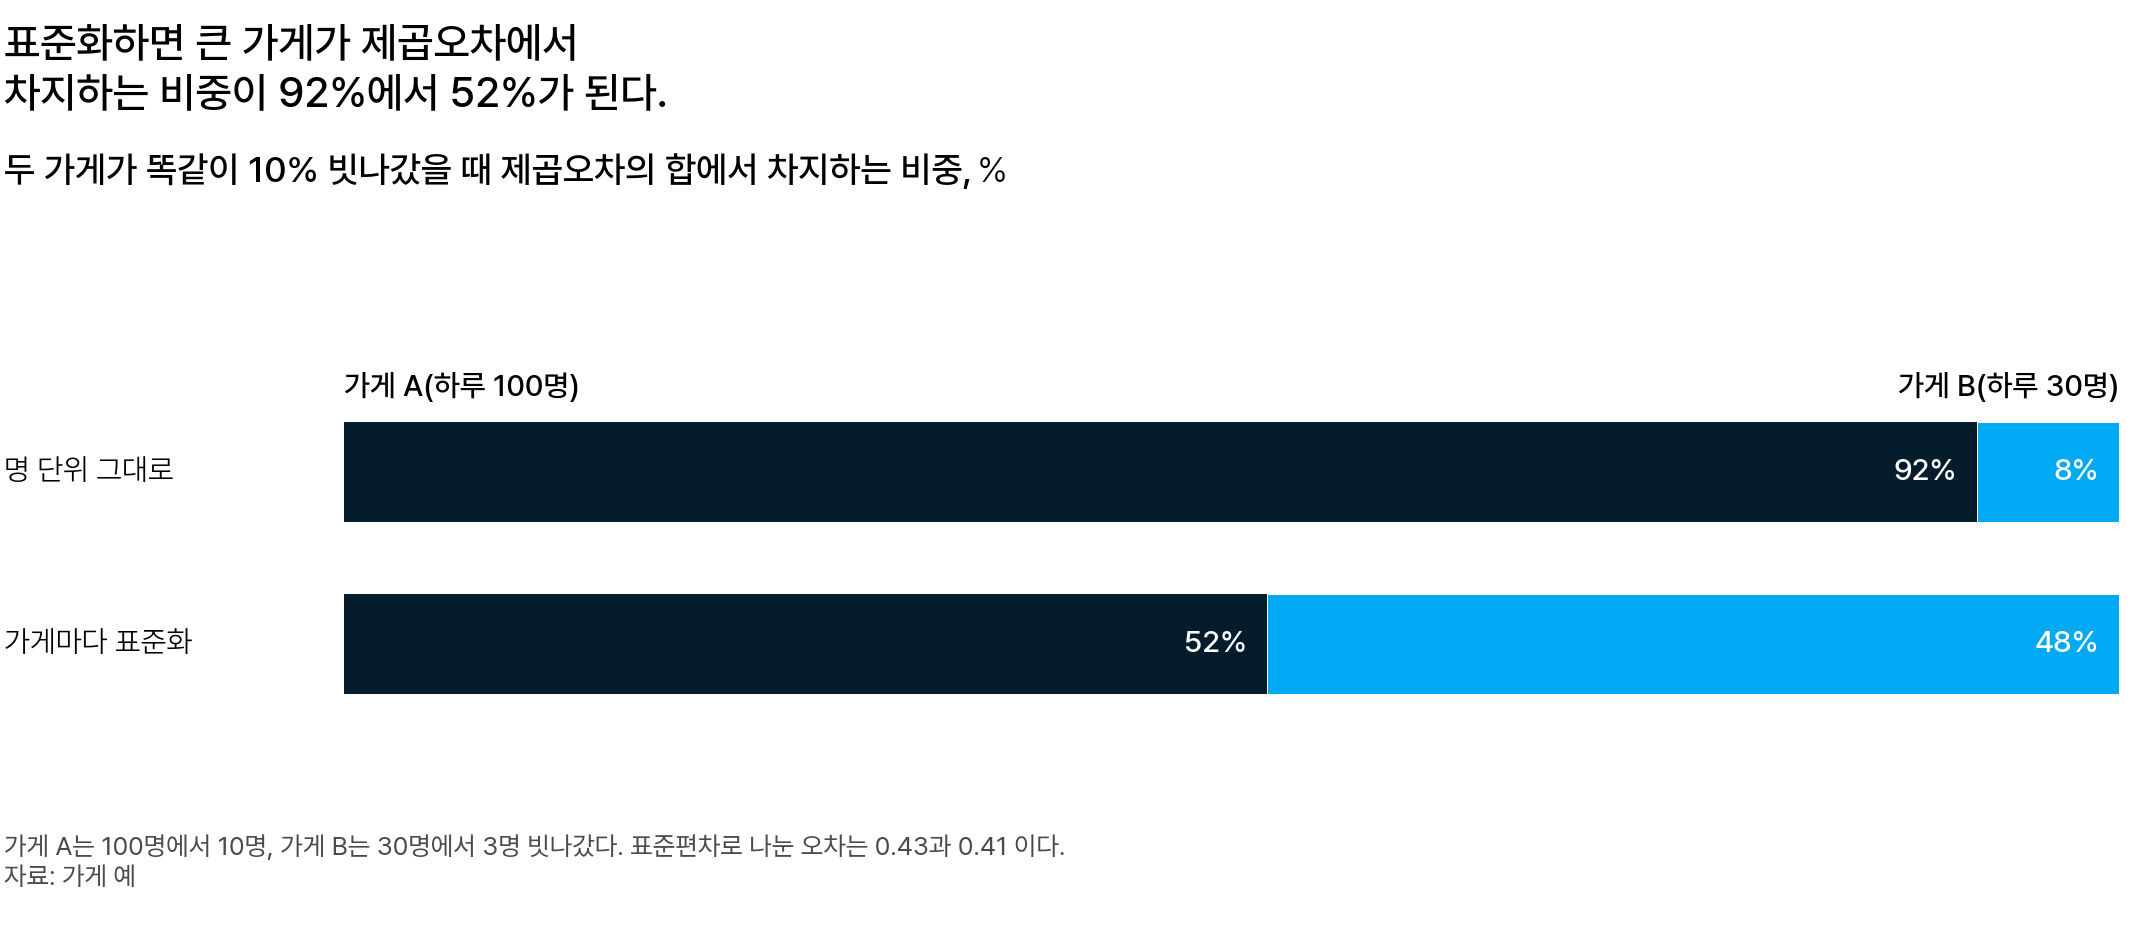

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 막대 하나는 두 가게가 똑같이 10% 빗나갔을 때의 제곱오차 합이다. 위는 명 단위 그대로이고 아래는 가게마다 표준화한 뒤다. 남색이 가게 A, 하늘색이 가게 B 다</em></p>

실제 값과 예측값에서 같은 평균을 빼므로 둘의 차에서 평균은 지워지고, 표준화한 오차는 명 단위 오차를 표준편차로 나눈 값입니다.

| 가게 | 10% 오차 | 표준화한 오차 | 제곱의 합에서 차지하는 비중 |
|---|---:|---:|---:|
| 가게 A | 10명 | 10 ÷ 23.2 ≈ 0.43 | 0.43² ÷ (0.43² + 0.41²) ≈ 52% |
| 가게 B | 3명 | 3 ÷ 7.3 ≈ 0.41 | 0.41² ÷ (0.43² + 0.41²) ≈ 48% |

두 오차가 0.43 과 0.41 로 비슷해져, 모델이 큰 가게의 오차만 먼저 줄이지 않습니다.

**표준화 전에는 92 대 8 이던 비중이 표준화 뒤에는 52 대 48 이 됩니다.**

### 표준화한 예측은 어떻게 명으로 되돌리나 [필수]

예측에 그 가게의 표준편차를 곱하고 평균을 더합니다.

모델의 입력과 출력은 모두 표준화 값이라, 채점하기 전에 명으로 되돌립니다.

$$
\hat y = \hat z \times \sigma_i + \mu_i
$$

- $\hat z$: 모델이 낸 표준화 예측
- $\hat y$: 명으로 되돌린 예측

모델이 두 가게 모두에 0.6 을 냈다고 해 봅니다.

| 가게 | 표준화 예측 | 되돌린 예측 |
|---|---:|---:|
| 가게 A | 0.6 | 0.6 × 23.2 + 85.7 ≈ 99.6명 |
| 가게 B | 0.6 | 0.6 × 7.3 + 25.7 ≈ 30.1명 |

채점할 7일의 값은 예측할 때 모르므로, 평균과 표준편차는 원점 전 자료로만 구합니다.

**같은 0.6 이 가게마다 그 가게의 평균과 표준편차로 다른 명 수가 됩니다.**

<details class="lms-extra"><summary>자세히 — 채점할 7일을 더해 평균을 구하면</summary>

채점할 7일까지 더해 평균과 표준편차를 구하면, 값이 조금만 달라져도 누수입니다.

가게 A 의 1～28일째 합은 600 × 4 = 2,400명입니다.

채점할 29～35일째는 수요일이 휴일이라 20명인 주라고 해 봅니다.

이 주의 합은 100 × 4 + 20 + 60 + 40 = 520명입니다.

| 평균을 구한 기간 | 셈 | 평균 |
|---|---:|---:|
| 원점 전 28일 | 2,400 ÷ 28 | 85.7명 |
| 채점할 7일까지 더한 35일 | (2,400 + 520) ÷ 35 | 83.4명 |

두 평균의 차 2.3명은 채점할 7일의 값에서 나왔습니다.

예측하는 날에는 채점할 7일의 값을 아직 모릅니다.

누수인지는 차이의 크기가 아니라, 예측하는 날에 그 값을 쓸 수 있는지로 정합니다.

그래서 차이가 작아도 채점할 7일을 더해 구한 평균은 누수입니다.

</details>

<div class="lms-summary">

**정리**

글로벌 모델은 여러 계열의 윈도를 한 표로 모아 모델 하나를 학습합니다. 규모가 다른 계열은 계열마다 표준화한 뒤 모읍니다.

**할 일**

- 계열마다 z = (y − μ) ÷ σ 로 바꾼 뒤 윈도를 한 표로 모읍니다
- 예측은 ẑ × σ + μ 로 명으로 되돌린 뒤 채점합니다

채점할 7일은 평균과 표준편차에도 포함하지 않습니다.

</div>

## 4. 다층 퍼셉트론(MLP)

윈도 한 행을 7일 예측으로 바꾸는 신경망 MLP 는 어떤 계산일까요?

### 베이스라인은 어떤 계산인가 [필수]

입력 28개에 수를 곱해 더하는 계산이고, 베이스라인마다 곱하는 수만 다릅니다.

가게의 29일째(월요일) 하루를 예측해 봅니다. 실제 손님 수는 100명입니다.

| 베이스라인 | 곱하는 수 | 예측값 |
|---|---|---:|
| 직전 7일 평균 | 22～28일째에 1/7 씩, 나머지에 0 | 85.7명 |
| 계절 나이브 | 22일째에 1, 나머지에 0 | 100명 |

입력마다 곱하는 수가 **가중치(weight)** 이고, 곱해 더한 값이 **가중합**입니다.

베이스라인의 가중치는 입력의 위치마다 미리 정해져 있어, 어느 윈도에서나 같은 위치에 같은 수를 곱합니다. 계절 나이브는 늘 1주일 전 값에 1 을 곱합니다.

그래서 2주 수요일이 휴일인 가게에서는 17일째에도 휴일의 값을 그대로 써서 80명 빗나갔습니다.

신경망은 가중치를 자료로 학습해 정하므로, 이런 날에 다른 날의 값도 함께 쓸 수 있습니다.

**베이스라인은 가중치가 미리 정해진 가중합이고, 신경망은 그 가중치를 자료로 정합니다.**

### 활성화 함수 ReLU 는 무엇을 하나 [필수]

가중합이 음수이면 0 으로 바꾸고, 양수이면 그대로 둡니다.

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Rectifier_and_softplus_functions.svg" width="480" height="349"/>
<p align="center"><em>▲ 가로축 x 는 ReLU 에 입력되는 값이고, 세로축 σ(x) 는 ReLU 가 내는 값이다. 그림의 σ 는 표준편차 σ 와 다른 기호다. 파란 선이 ReLU 이고, 초록 선 softplus 는 이 과정에서 쓰지 않는다 (출처: Wikipedia, Rectifier and softplus functions.svg)</em></p>

7일 전이 휴일이던 날에만 14일 전 값을 쓰는 계산을 만들어 봅니다.

먼저 14일 전 값에 1, 7일 전 값에 −1 을 곱해 더한 가중합을 구합니다.

| 예측할 날(실제 100명) | 14일 전 − 7일 전 | ReLU 를 거친 값 | 7일 전 값에 더하면 |
|---|---:|---:|---:|
| 17일째(7일 전이 휴일) | 100 − 20 = 80 | 80 | 20 + 80 = 100명 |
| 24일째(14일 전이 휴일) | 20 − 100 = −80 | 0 | 100 + 0 = 100명 |

ReLU 가 없으면 24일째는 100 − 80 = 20명이 됩니다.

가중합을 한 번 더 바꾸는 이런 계산이 **활성화 함수(activation function)** 이고, 이 과정은 ReLU 를 씁니다.

**ReLU 가 음수를 0 으로 바꿔, 7일 전이 휴일이던 날에만 14일 전 값과의 차가 예측에 더해집니다.**

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: ReLU 그래프</summary>

활성화 함수 둘을 한 좌표에 그린 그림이고, 이 과정은 파란 선만 씁니다.

| 그림의 글자 | 뜻 |
|---|---|
| $x$ | ReLU 에 입력되는 가중합 |
| $\sigma(x)$ | 활성화 함수가 내는 값. 표준편차 σ 와 다른 기호 |
| Rectifier(파란 선) | ReLU |
| Softplus(초록 선) | 이 과정에서 쓰지 않는 다른 활성화 함수 |
| Nonlinearities | 그림 제목 |

파란 선은 $x$ 가 0 보다 작으면 0 이고, 0 부터 기울기 1 로 올라갑니다.

| $x$ | 파란 선의 값 |
|---:|---:|
| −2 | 0 |
| 3 | 3 |

위 표의 −80 과 80 은 그림의 눈금 밖이고, 같은 규칙으로 계산합니다.

초록 선은 0 근처에서 꺾이지 않고 둥글게 올라갑니다.

</details>

### MLP 는 어떤 구조인가 [필수]

입력과 출력 사이에 은닉층을 둔, 층이 여럿인 신경망입니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Multi-Layer_Neural_Network-Vector.svg" alt="입력 3개가 원 3개인 은닉층을 지나 원 2개인 출력층으로 나가는 신경망" width="620" height="359"/>
<p align="center"><em>▲ 왼쪽 점 3개가 입력, 가운데 원 3개가 은닉층, 오른쪽 원 2개가 출력층인 작은 신경망. 원 하나는 앞 층 값의 가중합으로 만든 값 하나이고, 원으로 들어가는 화살표 하나가 가중치 하나다 (출처: Wikimedia Commons, Multi-Layer Neural Network-Vector.svg)</em></p>

**다층 퍼셉트론(multilayer perceptron, MLP)** 은 가중합과 ReLU 를 여러 층에 걸쳐 되풀이하는 신경망입니다.

입력과 출력 사이의 층이 **은닉층(hidden layer)** 이고, 은닉층의 값 하나는 앞 층 값의 가중합이 ReLU 를 거친 값입니다.

마지막 **출력층(output layer)** 은 은닉층 값의 가중합으로 예측값을 냅니다.

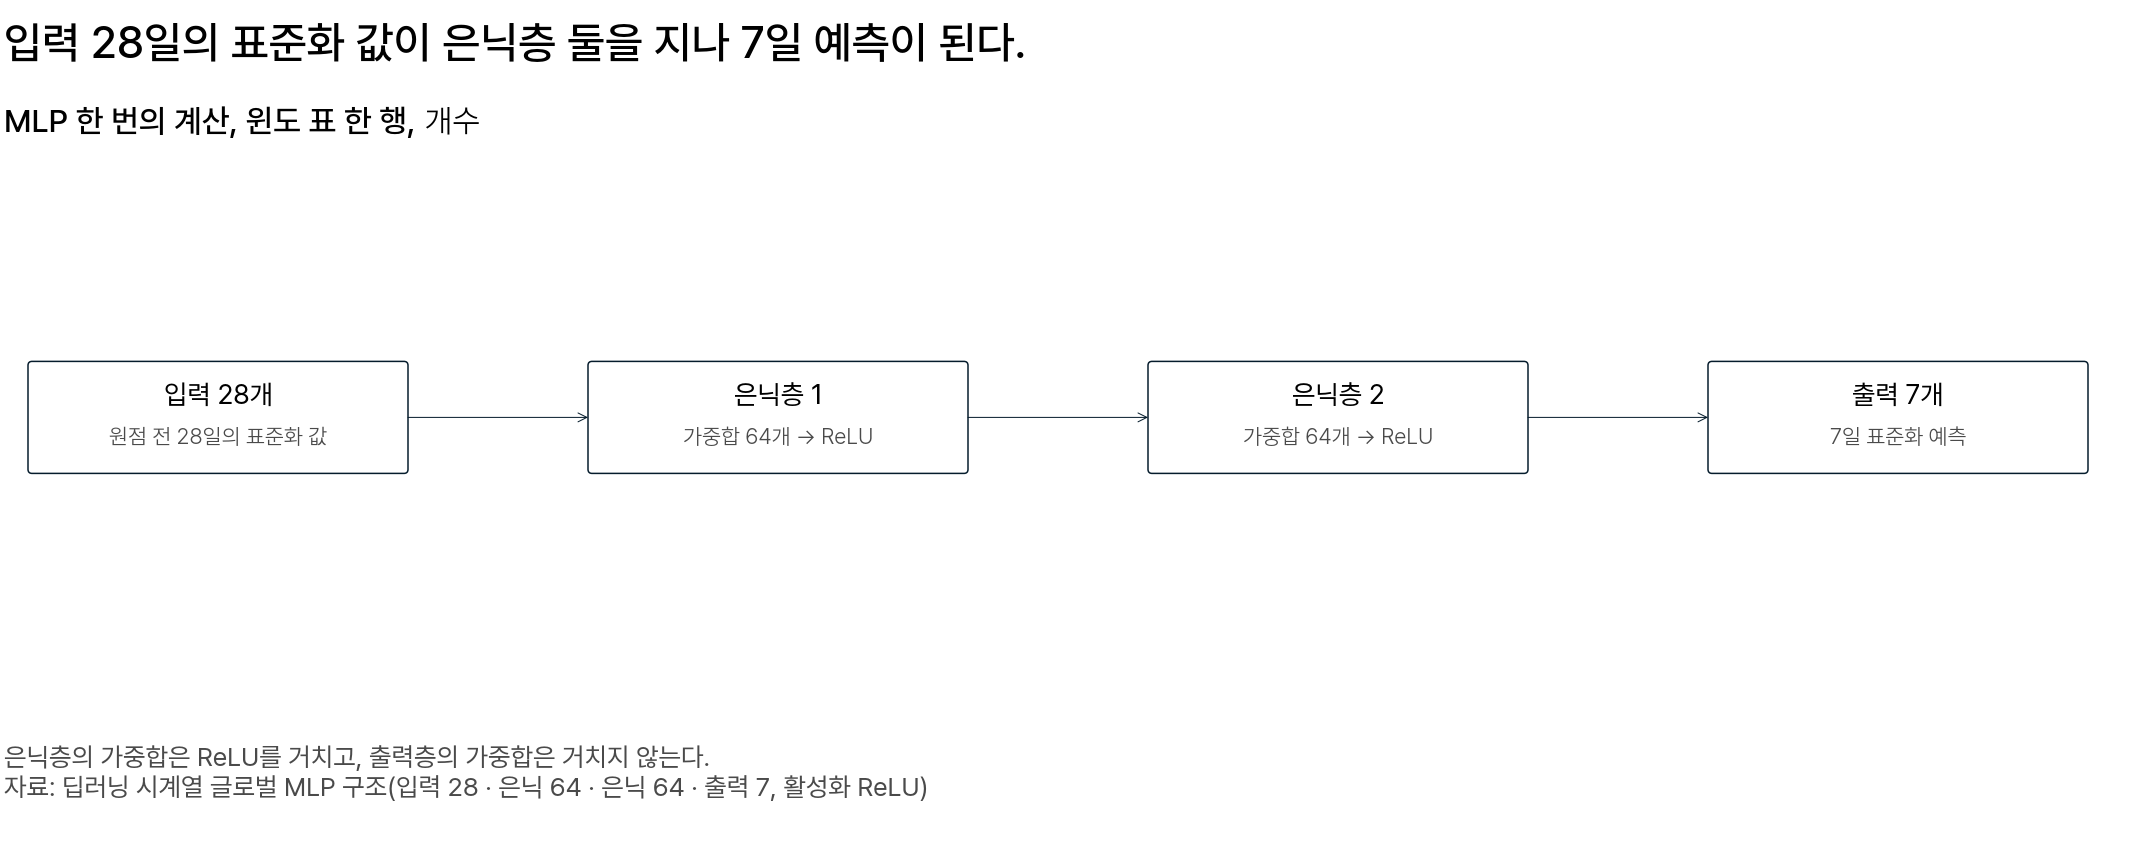

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 이 과정의 MLP 한 번의 계산. 상자는 층의 출력이고, 원점 전 28일의 표준화 값이 은닉층 둘을 지나 7일의 표준화 예측이 된다</em></p>

은닉층의 값 개수는 학습 전에 정해 두는 설정이고, 이 과정은 층마다 64개입니다.

**이 과정의 MLP 는 입력 28개가 은닉층 둘을 지나 출력 7개가 됩니다.**

<details class="lms-extra"><summary>자세히 — 은닉층의 값 하나를 식으로 적으면</summary>

첫 은닉층의 값 하나는 입력 28개로 이렇게 계산합니다.

$$
a = \text{ReLU}(w_1 x_1 + \cdots + w_{28} x_{28} + b)
$$

- $x_1, \dots, x_{28}$: 입력 28개
- $w_1, \dots, w_{28}$: 입력마다 곱하는 가중치
- $b$: 가중합에 더하는 편향
- $a$: 은닉층의 값 하나

가중합에 더하는 수 $b$ 가 **편향(bias)** 이고, 회귀식의 절편과 같은 일을 합니다.

입력마다 가중치를 곱해 더하고 편향을 더한 뒤, 음수이면 0 으로 바꾼다는 뜻입니다.

첫 은닉층은 가중치와 편향이 서로 다른 이런 값을 64개 냅니다.

둘째 은닉층은 그 64개를 입력으로 같은 계산을 합니다.

출력층은 둘째 은닉층의 64개로 가중합 7개를 냅니다.

출력은 음수일 수 있어 ReLU 를 거치지 않습니다.

선형회귀는 가중합 하나로 예측합니다.

MLP 는 ReLU 를 거친 값을 다시 가중합합니다.

그래서 가중합이 0 을 넘을 때만 그 값을 예측에 반영하는 계산도 할 수 있습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: 작은 신경망 그림과 이 과정의 MLP</summary>

원과 화살표로 그린 첫 그림은 층이 셋인 작은 신경망입니다.

| 그림의 요소 | 뜻 |
|---|---|
| 왼쪽 점 3개 | 입력 |
| hidden layer(원 3개) | 은닉층 |
| output layer(원 2개) | 출력층 |
| 원 하나 | 앞 층 값의 가중합으로 만든 값 하나 |
| 원으로 들어가는 화살표 하나 | 가중치 하나 |
| 출력층 오른쪽의 화살표 둘 | 신경망이 내는 값 둘 |

그림은 왼쪽에서 오른쪽으로 읽고, 원으로 들어가는 화살표의 수가 가중치의 수입니다.

입력 3개에서 은닉층의 원 3개로 가는 화살표가 3 × 3 = 9개입니다.

은닉층의 원 3개에서 출력층의 원 2개로 가는 화살표가 3 × 2 = 6개입니다.

더하면 가중치는 15개입니다.

$$
3 \times 3 + 3 \times 2 = 15
$$

이 과정의 MLP 는 입력 28개, 원이 64개인 은닉층 둘, 출력 7개입니다.

가중합마다 수 하나를 더하는데, 이 수를 편향이라 부릅니다.

| 층 | 가중치 | 편향 |
|---|---:|---:|
| 첫 은닉층 | 28 × 64 = 1,792 | 64 |
| 둘째 은닉층 | 64 × 64 = 4,096 | 64 |
| 출력층 | 64 × 7 = 448 | 7 |

이 MLP 가 정하는 가중치와 편향은 표의 수를 모두 더한 6,471개입니다.

</details>

### 은닉층의 값 둘이면 가게의 어느 날까지 맞히나 [선택]

아래 표의 네 날을 모두 맞히고, 계절 나이브가 80명 빗나간 17일째도 맞힙니다.

2주 수요일이 휴일인 가게에서, 예측할 날의 7일 전 값과 14일 전 값만 입력한다고 해 봅니다.

「활성화 함수 ReLU 는 무엇을 하나」의 계산은 은닉층의 값 둘로 적을 수 있습니다.

- $a_1$ = ReLU(7일 전)
- $a_2$ = ReLU(14일 전 − 7일 전)
- 예측값 = $a_1 + a_2$

| 예측할 날 | 7일 전 | 14일 전 | $a_1$ | $a_2$ | $a_1 + a_2$ | 실제 |
|---|---:|---:|---:|---:|---:|---:|
| 17일째(3주 수요일) | 20 | 100 | 20 | 80 | 100 | 100 |
| 24일째(4주 수요일) | 100 | 20 | 100 | 0 | 100 | 100 |
| 31일째(다음 수요일) | 100 | 100 | 100 | 0 | 100 | 100 |
| 27일째(4주 토요일) | 60 | 60 | 60 | 0 | 60 | 60 |

**은닉층의 값 둘이면, 7일 전이 휴일이던 날에만 14일 전 값을 쓰는 계산을 적을 수 있습니다.**

### 가중치는 어떻게 정하나 [필수]

예측이 틀린 정도가 줄어드는 쪽으로 가중치를 조금씩 고칩니다.

1주일 전 월요일의 100명에 가중치 $w$ 하나를 곱해 29일째를 예측해 봅니다. 정답은 100명입니다.

| $w$ | 예측값 | 오차의 제곱 |
|---:|---:|---:|
| 0.5 | 50명 | 2,500 |
| 0.6 | 60명 | 1,600 |
| 1.0 | 100명 | 0 |
| 1.1 | 110명 | 100 |

예측이 틀린 정도를 수 하나로 모은 값이 **손실(loss)** 이고, 여기서는 오차의 제곱입니다.

$w$ 가 0.5 이면 키우는 쪽이, 1.1 이면 줄이는 쪽이 손실을 줄입니다. 이렇게 손실이 줄어드는 쪽으로 가중치를 조금씩 고치는 방법이 **경사하강법(gradient descent)** 입니다.

입력이 하나뿐인 이 예에서는 손실이 0 인 $w$ = 1 이 계절 나이브와 같습니다. MLP 의 가중치는 첫 은닉층에만 입력 28개 × 값 64개 = 1,792개이고, 모두 같은 방법으로 함께 고칩니다.

학습 윈도 전체를 한 번씩 써서 가중치를 고치는 한 차례가 **에폭(epoch)** 입니다.

글로벌 모델에서는 이렇게 정한 가중치를 모든 계열이 함께 씁니다.

**가중치는 손실이 줄어드는 쪽으로 조금씩 고치는 일을 되풀이해 정합니다.**

### 새 날에도 맞는지는 무엇으로 확인하나 [필수]

학습에 쓰지 않고 떼어 둔 날의 손실로 확인합니다.

가중치를 학습에 쓴 날에 맞춰 고쳐서, 학습에 쓴 날의 손실이 낮아도 새 날에는 덜 맞을 수 있습니다.

떼어 두는 날은 원점 직전의 며칠입니다. 이 구간이 **검증 구간(validation period)** 이고, 이 구간의 손실이 검증 손실입니다.

| 손실 | 계산하는 날 | 가중치를 고치는 데 쓰나 |
|---|---|---|
| 학습 손실 | 학습에 쓴 날 | 씀 |
| 검증 손실 | 검증 구간 | 쓰지 않음 |

**검증 손실이 낮아야 새 날에도 맞는다고 말합니다.**

### 학습을 오래 하면 무엇이 문제인가 [필수]

학습에 쓴 날에만 맞고, 새 날에는 덜 맞게 됩니다.

멈추지 않고 8에폭까지 학습했더니 손실이 아래와 같았다고 해 봅니다.

| 에폭 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 학습 손실 | 50 | 30 | 20 | 14 | 10 | 7 | 5 | 4 |
| 검증 손실 | 52 | 34 | 25 | 21 | 22 | 24 | 27 | 30 |

학습 손실은 8에폭까지 줄어듭니다. 검증 손실은 4에폭의 21 이 가장 낮고, 5에폭부터 다시 높아집니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Overfitting_svg.svg" alt="가로축 학습 진행, 세로축 오차인 좌표에 계속 내려가는 파란 곡선과 내려갔다 다시 오르는 빨간 곡선, 빨간 곡선의 가장 낮은 곳에 세로선" width="610" height="450"/>
<p align="center"><em>▲ 가로축은 학습을 진행한 정도이고 세로축 ε 는 오차다. 파란 선이 학습 오차, 빨간 선이 검증 오차이고, 가는 세로선이 검증 오차가 가장 낮은 곳이다 (출처: Wikimedia Commons, Overfitting svg.svg)</em></p>

**학습 윈도에만 맞고 새 날에는 덜 맞게 되는 것이 과적합(overfitting)입니다.**

<details class="lms-extra"><summary>더 깊이 — 그림 읽기: 학습 오차와 검증 오차 곡선</summary>

학습을 진행하는 동안 오차 둘이 어떻게 달라지는지 그린 그림입니다.

| 그림의 요소 | 뜻 |
|---|---|
| 세로축 ε | 오차 |
| 가로축 | 학습을 진행한 정도 |
| 파란 선 | 학습 오차 |
| 빨간 선 | 검증 오차 |
| 가는 세로선과 경고 표시 | 검증 오차가 가장 낮은 곳 |

그림은 왼쪽에서 오른쪽으로 읽습니다.

파란 선은 계속 내려가고, 빨간 선은 내려갔다가 세로선을 지나 다시 올라갑니다.

위 표에서는 4에폭이 세로선이 있는 곳입니다.

학습 오차가 낮을수록 좋은 모델이라고 생각하기 쉽습니다.

학습 오차만 낮다면 학습에 쓴 날에만 맞는 것일 수 있습니다.

그래서 학습을 멈춘 뒤에는 검증 오차가 가장 낮았던 때(세로선)의 가중치를 씁니다.

이 그림에서는 곡선의 모양만 알 수 있고, 실제 오차의 값은 자료와 설정마다 다릅니다.

</details>

### 학습은 언제 멈추나 [필수]

검증 손실이 몇 에폭 이어서 나아지지 않을 때 멈춥니다.

앞의 표에서, 3에폭 이어서 나아지지 않으면 멈춘다고 해 봅니다.

| 에폭 | 4 | 5 | 6 | 7 |
|---|---:|---:|---:|---:|
| 검증 손실 | 21 | 22 | 24 | 27 |

5 · 6 · 7에폭이 모두 4에폭보다 높으므로 7에폭에서 멈추고, 4에폭의 가중치를 씁니다. 이 규칙이 **조기 종료(early stopping)** 입니다.

멈출 에폭을 채점하는 7일의 손실로 고르면, 채점할 정답을 미리 쓴 누수입니다.

이 과정의 MLP 는 원점 직전 56일을 검증 구간으로 두고, 5에폭 이어서 나아지지 않으면 멈춥니다.

**멈출 에폭은 검증 구간의 손실로 고르고, 채점하는 7일로 고르지 않습니다.**

### 같은 설정으로 다시 학습하면 결과가 같은가 [필수]

같지 않습니다. 처음 가중치와 학습 윈도를 쓰는 순서를 난수로 정하기 때문입니다.

이 난수의 출발값이 **시드(seed)** 이고, 시드가 바뀌면 학습한 가중치와 예측도 달라집니다.

그래서 은닉층의 값 개수나 손실 같은 설정을 비교할 때는, 설정마다 시드 다섯 개(0～4)로 학습합니다.

세 설정의 MASE 가 아래와 같았다고 해 봅니다.

| 시드 | 0 | 1 | 2 | 3 | 4 |
|---|---:|---:|---:|---:|---:|
| 설정 가 | 0.8 | 0.9 | 0.7 | 0.8 | 0.9 |
| 설정 나 | 0.9 | 0.8 | 0.9 | 0.9 | 0.8 |
| 설정 다 | 1.0 | 1.1 | 0.9 | 1.0 | 1.1 |

설정 가의 MASE 는 설정 다보다 다섯 번 모두 낮아, 설정 가가 낫다고 말합니다.

설정 나와 비교하면 세 번만 낮아, 어느 쪽이 낫다고 말하지 않습니다.

**다섯 번 모두 같은 쪽의 MASE 가 낮을 때만 그쪽이 낫다고 말합니다.**

<div class="lms-summary">

**정리**

MLP 에서는 입력이 가중합과 ReLU 로 된 은닉층을 지나 7일 예측이 되고, 가중치는 손실이 줄어드는 쪽으로 고쳐 정합니다.

**할 일**

- 멈출 에폭은 검증 구간의 손실로 고르고, 채점하는 7일로 고르지 않습니다

시드가 바뀌면 결과도 달라지므로, 두 설정은 시드 0～4 모두에서 같은 쪽의 MASE 가 낮은지 확인합니다.

</div>

## 5. 손실 MSE 와 MAE

신경망을 학습할 때 손실은 MSE 와 MAE 가운데 무엇으로 둘까요?

빗나간 크기를 제곱해 평균한 값이 **평균 제곱 오차(mean squared error, MSE)** 입니다.

### MSE 와 MAE 는 어느 값에서 가장 작은가 [필수]

2주 수요일이 휴일인 가게의 네 수요일은 100 · 20 · 100 · 100명입니다.

손실에 따라 예측이 어느 쪽으로 가는지 알아보려고, 네 날 모두를 같은 값 하나로 예측한다고 해 봅니다. 이 예측값을 $c$ 라 부릅니다.

$c$ 가 100명이면 휴일이던 날만 80명 빗나가고, 제곱하면 6,400 입니다.

> **[예측] 빗나간 크기를 제곱해 더한 값이 가장 작은 $c$ 는 얼마일까요?**
>
> 1. 평소 세 날의 100명
> 2. 100명보다 낮은 80명
> 3. 휴일의 20명
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

100명보다 낮은 80명입니다.

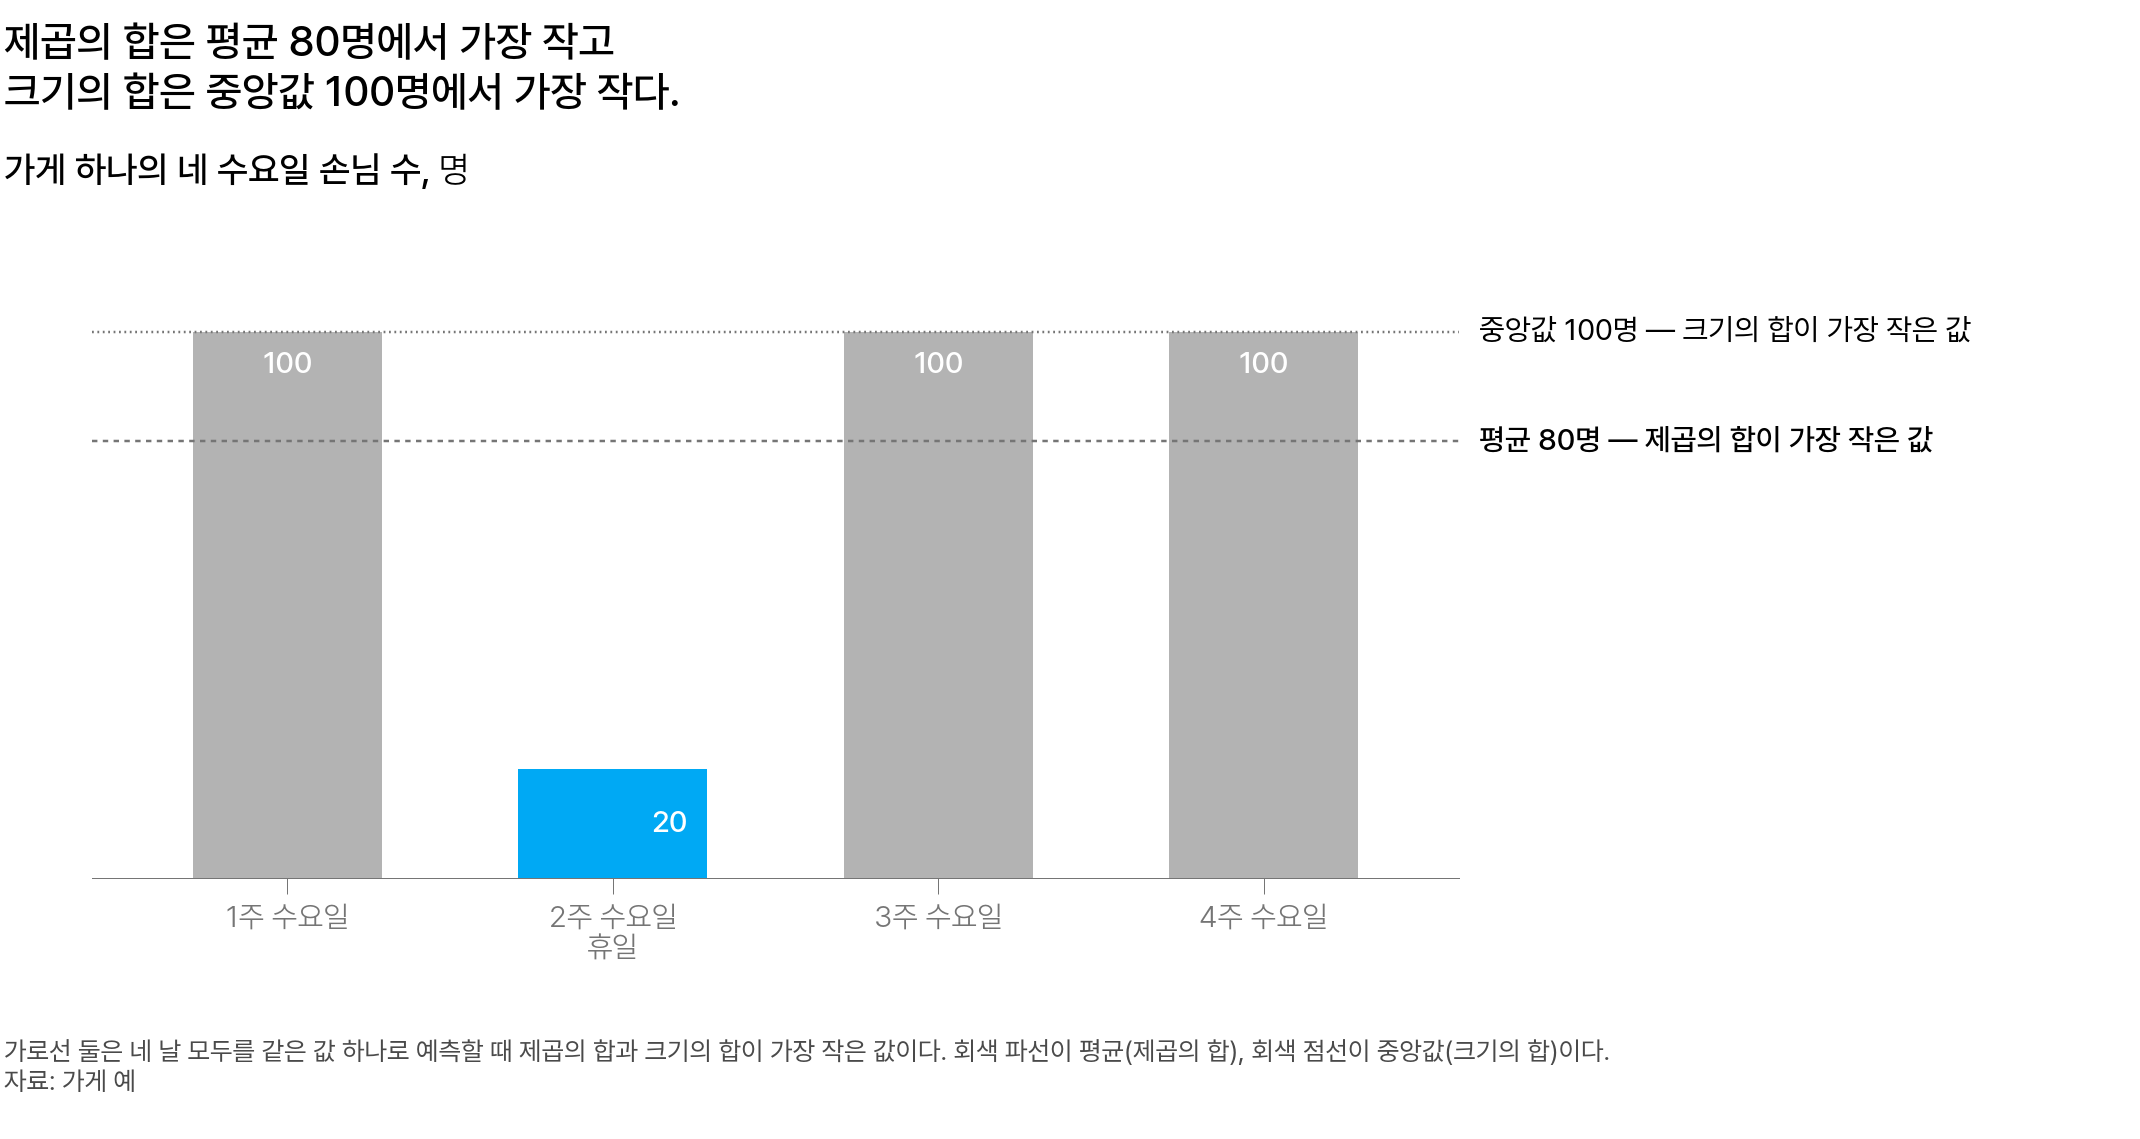

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 네 수요일이고 세로축은 손님 수(명)다. 하늘색 막대가 휴일이던 2주 수요일이다. 회색 파선은 네 날의 평균 80명이고, 회색 점선은 중앙값 100명이다</em></p>

| $c$ | 빗나간 크기 | 크기의 합 | 제곱의 합 |
|---|---|---:|---:|
| 100명 | 0 · 80 · 0 · 0 | 80 | 6,400 |
| 80명 | 20 · 60 · 20 · 20 | 120 | 4,800 |
| 20명 | 80 · 0 · 80 · 80 | 240 | 19,200 |

세 후보뿐 아니라 어느 값과 비교해도, 제곱의 합은 80명에서 크기의 합은 100명에서 가장 작습니다.

80명은 네 날의 평균입니다. 100명은 크기 순으로 놓았을 때 가운데 값인 **중앙값(median)** 입니다.

제곱의 합과 크기의 합을 4 로 나눈 평균이 손실 MSE 와 MAE 입니다.

**값 하나로 예측하면 MSE 는 평균에서, MAE 는 중앙값에서 가장 작습니다.**

<details class="lms-extra"><summary>자세히 — MSE 와 MAE 를 식으로 적으면</summary>

한 날의 오차는 정답에서 예측값을 뺀 값입니다.

$$
e_k = y_k - \hat y_k
$$

- $y_k$: $k$번째 정답
- $\hat y_k$: $k$번째 예측값
- $k$: 값의 번호(1～$N$)

MSE 는 오차 제곱의 평균입니다.

$$
\text{MSE} = \frac{1}{N}\sum_{k=1}^{N} e_k^{2}
$$

MAE 는 오차의 크기를 모두 더해 개수로 나눈 평균입니다.

$$
\text{MAE} = \frac{1}{N}\sum_{k=1}^{N} |e_k|
$$

- $N$: 한 번에 비교하는 값의 개수

네 수요일을 대입하면 $N$ 은 4 이고, 두 값은 아래와 같습니다.

| $c$ | MSE | MAE |
|---|---:|---:|
| 80명 | 4,800 ÷ 4 = 1,200 | 120 ÷ 4 = 30명 |
| 100명 | 6,400 ÷ 4 = 1,600 | 80 ÷ 4 = 20명 |

MSE 는 80명에서, MAE 는 100명에서 더 작습니다.

PyTorch 에서 MSE 는 `nn.MSELoss`, MAE 는 `nn.L1Loss` 로 씁니다.

</details>

### 왜 제곱으로 세면 예측값이 평균 쪽으로 내려가나 [선택]

제곱으로 세면 크게 빗나간 하루가 더 크게 반영되기 때문입니다.

$c$ 를 100명에서 80명으로 내리면 이렇게 달라집니다.

| 세는 방식 | 휴일 하루 | 평소 세 날 | 합 |
|---|---|---|---|
| 크기 | 80 → 60 | 0 → 20 씩 | 80 → 120 |
| 제곱 | 6,400 → 3,600 | 0 → 400 씩 | 6,400 → 4,800 |

제곱으로 세면 휴일 하루에서 2,800 이 줄고, 평소 세 날에서 1,200 이 늘어납니다.

크기로 세면 20 이 줄고 60 이 늘어, 합이 오히려 커집니다.

$c$ 가 80명일 때 휴일 하루는 제곱의 합에서 3,600 ÷ 4,800 = 75% 를 차지합니다.

**제곱의 합에서는 휴일 하루가 75% 를 차지해, 이 하루의 오차를 줄이는 쪽으로 예측값이 내려갑니다.**

### 입력이 같은데 정답이 다른 윈도가 있으면 예측은 어느 값이 되나 [필수]

입력이 같은 윈도 10개가 있다고 해 봅니다. 9개는 다음 수요일이 평소라 정답이 100명이고, 1개는 휴일이라 20명입니다.

입력에는 다음 주가 휴일인지가 없습니다. 입력이 같으면 예측도 같아, 모델은 10개 모두에 같은 값을 냅니다.

MSE 가 가장 작은 값은 10개의 평균인 92명입니다.

> **[예측] 92명을 예측하면, 윈도 10개 가운데 실제보다 낮게 예측한 것은 몇 개일까요?**
>
> 1. 1개
> 2. 5개
> 3. 9개
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

9개입니다. 정답이 100명인 9개를 모두 8명 낮게 예측합니다.

| 손실 | 손실이 가장 작은 값 | 평소 9개 | 휴일 1개 | 이럴 때 쓴다 |
|---|---|---|---|---|
| MSE | 평균 (9 × 100 + 20) ÷ 10 = 92명 | 8명씩 낮게 예측 | 72명 높게 예측 | 드문 큰 오차의 비용이 클 때 |
| MAE | 중앙값 100명 | 모두 맞힘 | 80명 높게 예측 | 대부분의 날을 맞히는 것이 중요할 때 |

MSE 로 학습하면 크게 빗나가는 휴일의 오차부터 줄어, 그 대신 평소 9개의 예측이 낮아집니다.

**MSE 로 학습하면 드문 휴일 하나 때문에 평소 아홉 번을 낮게 예측합니다.**

### 손실은 무엇에 맞춰 고르나 [필수]

채점 지표와 오차를 세는 방식이 같은 손실을 고릅니다.

**손실**은 학습할 때 모델이 줄이는 값이고, **채점 지표**는 학습이 끝난 뒤 예측을 채점하는 값입니다.

| 오차를 세는 방식 | 손실 | 채점 지표 |
|---|---|---|
| 제곱 | MSE | RMSE = $\sqrt{\text{MSE}}$ |
| 크기 | MAE | MAE, MASE = MAE ÷ $Q_i$ |

- 제곱근은 크기 순서를 바꾸지 않아, MSE 가 가장 작은 예측이 RMSE 도 가장 작습니다
- MASE 는 MAE 를 정해진 수 $Q_i$ 로 나눈 값이라, 한 계열의 MAE 가 줄면 MASE 도 줄어듭니다

**채점을 MASE 로 하면 손실도 MAE 로 둡니다.**

<details class="lms-extra"><summary>자세히 — 윈도 10개를 MAE 와 RMSE 로 채점하면</summary>

입력이 같은 윈도 10개를 두 예측값으로 채점해 봅니다.

| 예측값 | MAE | RMSE |
|---|---:|---:|
| 92명 | (9 × 8 + 72) ÷ 10 = 14.4명 | √576 = 24명 |
| 100명 | 80 ÷ 10 = 8명 | √640 ≈ 25.3명 |

MAE 로 채점하면 100명이, RMSE 로 채점하면 92명이 덜 빗나갑니다.

MSE · RMSE · MAE 는 단위와 크기도 다릅니다. 이틀의 오차가 10명과 30명이라고 해 봅니다.

| 값 | 계산 | 결과 |
|---|---|---:|
| MSE | (10² + 30²) ÷ 2 | 500명² |
| RMSE | √500 | 약 22.4명 |
| MAE | (10 + 30) ÷ 2 | 20명 |

MSE 는 단위가 명² 이라 그대로 읽기 어렵고, RMSE 와 MAE 는 명 단위입니다.

제곱한 뒤 평균하면 30명 빗나간 날이 더 크게 반영되어, RMSE 가 MAE 보다 큽니다.

</details>

<div class="lms-summary">

**정리**

값 하나로 예측하면 MSE 는 평균에서, MAE 는 중앙값에서 가장 작습니다. 드문 휴일이 있으면 MSE 가 가장 작아지는 예측값은 평소 날의 값보다 낮아집니다. MAE 가 가장 작아지는 예측값은 평소 날의 값 그대로입니다.

**할 일**

- 실습의 학습 함수 `fit_global` 은 `loss="mae"` 로 부릅니다

채점을 MASE 로 하면 손실도 MAE 로 둡니다.

</div>

## 6. 서울 지하철 100개 역에 글로벌 MLP 를 쓰면

100개 역을 한 모델로 학습한 신경망을 다음 주 역별 인력 예측에 쓸까요?

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Seoul_subway_linemap_ko.svg" alt="서울 지하철 노선도" width="480" height="546"/>
<p align="center"><em>▲ 서울 지하철 노선도. 이 과정에서 예측하는 100개 역은 노선 13개에 걸쳐 있다 (출처: Wikimedia Commons, Seoul subway linemap ko.svg)</em></p>

가게 예로 한 계산을 같은 차례로 서울 지하철 100개 역에 합니다.

**여기부터 나오는 수는 모두 서울 지하철 100개 역의 승차 기록과, 예측 원점 5개에서 채점한 값입니다.**

### 100개 역 표는 어떤 자료인가 [필수]

11년 반 동안 하루도 빠지지 않고 기록된 100개 역의 하루 승차 인원입니다.

| 날짜 | 2호선 강남 | 2호선 잠실 | ⋯ | 경부선 구로 |
|---|---:|---:|:---:|---:|
| 2015-01-01(목, 신정) | 39,173 | 43,883 | ⋯ | 11,215 |
| ⋮ | ⋮ | ⋮ | | ⋮ |
| 2026-06-23(화) | 94,098 | 84,590 | ⋯ | 18,718 |

<p align="center"><em>▲ 100개 역 표의 두 행과 세 열 (출처: 서울열린데이터광장 「서울시 지하철 호선별 역별 승하차 인원 정보」)</em></p>

기간은 2015-01-01～2026-06-30 의 4,199일입니다.

기록이 끊기지 않은 역 가운데 2024년까지 평균 승차가 가장 큰 100개 역을 골랐습니다.

100개 역 × 4,199일 = 419,900개 값에 빈칸이 없습니다.

가게 하나가 여기서는 역 하나이고, 손님 수가 승차 인원입니다.

**이 표를 100개 역 표라 부르고, 모든 방식을 이 표 하나로 계산합니다.**

<details class="lms-extra"><summary>더 깊이 — 원자료와 자료를 고른 규칙</summary>

원자료는 2,480,294행입니다.

한 행은 한 호선·역의 하루 기록이고, 열은 날짜 `date`·호선 `line`·역 `station`·승차 `board`·하차 `alight` 입니다.

| `date` | `line` | `station` | `board` | `alight` |
|---|---|---|---:|---:|
| 2016-10-17 | 2호선 | 잠실 | 81,660 | 75,743 |
| 2026-06-23 | 2호선 | 강남 | 94,098 | 91,592 |
| 2026-06-23 | 2호선 | 잠실(송파구청) | 84,590 | 83,272 |
| 2026-06-23 | 8호선 | 잠실(송파구청) | 20,555 | 23,664 |

본문 표의 2026-06-23 행 강남·잠실 값이 위 원자료 두 행의 `board` 이고, 하차 `alight` 는 쓰지 않습니다.

- **출처**: 서울열린데이터광장 「서울시 지하철 호선별 역별 승하차 인원 정보」(OA-12914, 공공누리 제1유형)
- **정제**: 역 이름 뒤의 괄호 별칭을 뗍니다. 2호선 잠실은 2016-10-18 부터 「잠실(송파구청)」으로 적혀 있어, 떼어야 4,199일이 한 역으로 이어집니다. 9호선 2～3단계 구간의 두 호선 표기도 하나로 맞춥니다. 같은 날짜·호선·역이 두 번 적힌 370건은 더해 한 행으로 합치므로, 370행이 줄어 2,479,924행이 됩니다.
- **계열**: 계열 하나는 (호선, 역) 한 쌍의 날짜별 승차입니다. 원자료 2,480,294행에서 계열 639개가 나옵니다.
- **역**: 2015-01-01 과 2026-06-30 에 기록이 있고, 4,199일 가운데 4,190일 이상 기록된 계열이 521개입니다. 이 521개 안에서 2024-12-31 까지의 평균 승차가 큰 100개를 고릅니다.
- **왜 이렇게 고르나**: 역을 고른 기준일 2024-12-31 이 모든 예측 원점보다 앞이라, 채점할 7일의 승차가 역을 고르는 데 쓰이지 않습니다.
- **빈칸**: 조건만으로는 빈칸이 없다고 보장되지 않아, 고른 100개 역에 빈칸이 없는지 따로 확인했습니다(0개). 채운 값도 없습니다.
- **같은 이름의 역**: 같은 이름이라도 호선이 다르면 다른 역입니다(위 표의 2호선 잠실과 8호선 잠실). 강남은 2호선 강남 하나입니다.

원자료의 `line` 은 1호선 가운데 서울역～청량리 구간만 「1호선」으로 적습니다.

나머지 구간은 경부선·경인선·경원선 같은 철도 노선 이름으로 적습니다.

그래서 경부선 구로는 1호선 구로역이고, 2호선 구로디지털단지와 다른 역입니다.

2026-06-23 까지 1년 평균 승차는 잠실이 80,499명으로 가장 크고, 구로가 16,594명으로 가장 작습니다.

이 1년만 계산하면 첫 열 강남(77,858명)보다 잠실이 큽니다.

열 순서는 2024년까지 평균으로 매겨 강남이 첫 열입니다.

원자료는 매일 3일 전 자료까지 공개되므로, 실제 운영이라면 예측 원점 2026-06-24 에 6월 21일까지만 압니다.

이 과정에서는 원점 전날인 6월 23일까지 안다고 가정했고, 그만큼 실제 운영보다 유리한 조건입니다.

</details>

### 채점하는 다섯 주에는 평일 공휴일이 며칠 있나 [필수]

다섯 주 가운데 세 주에 평일 공휴일이 모두 6일 있습니다.

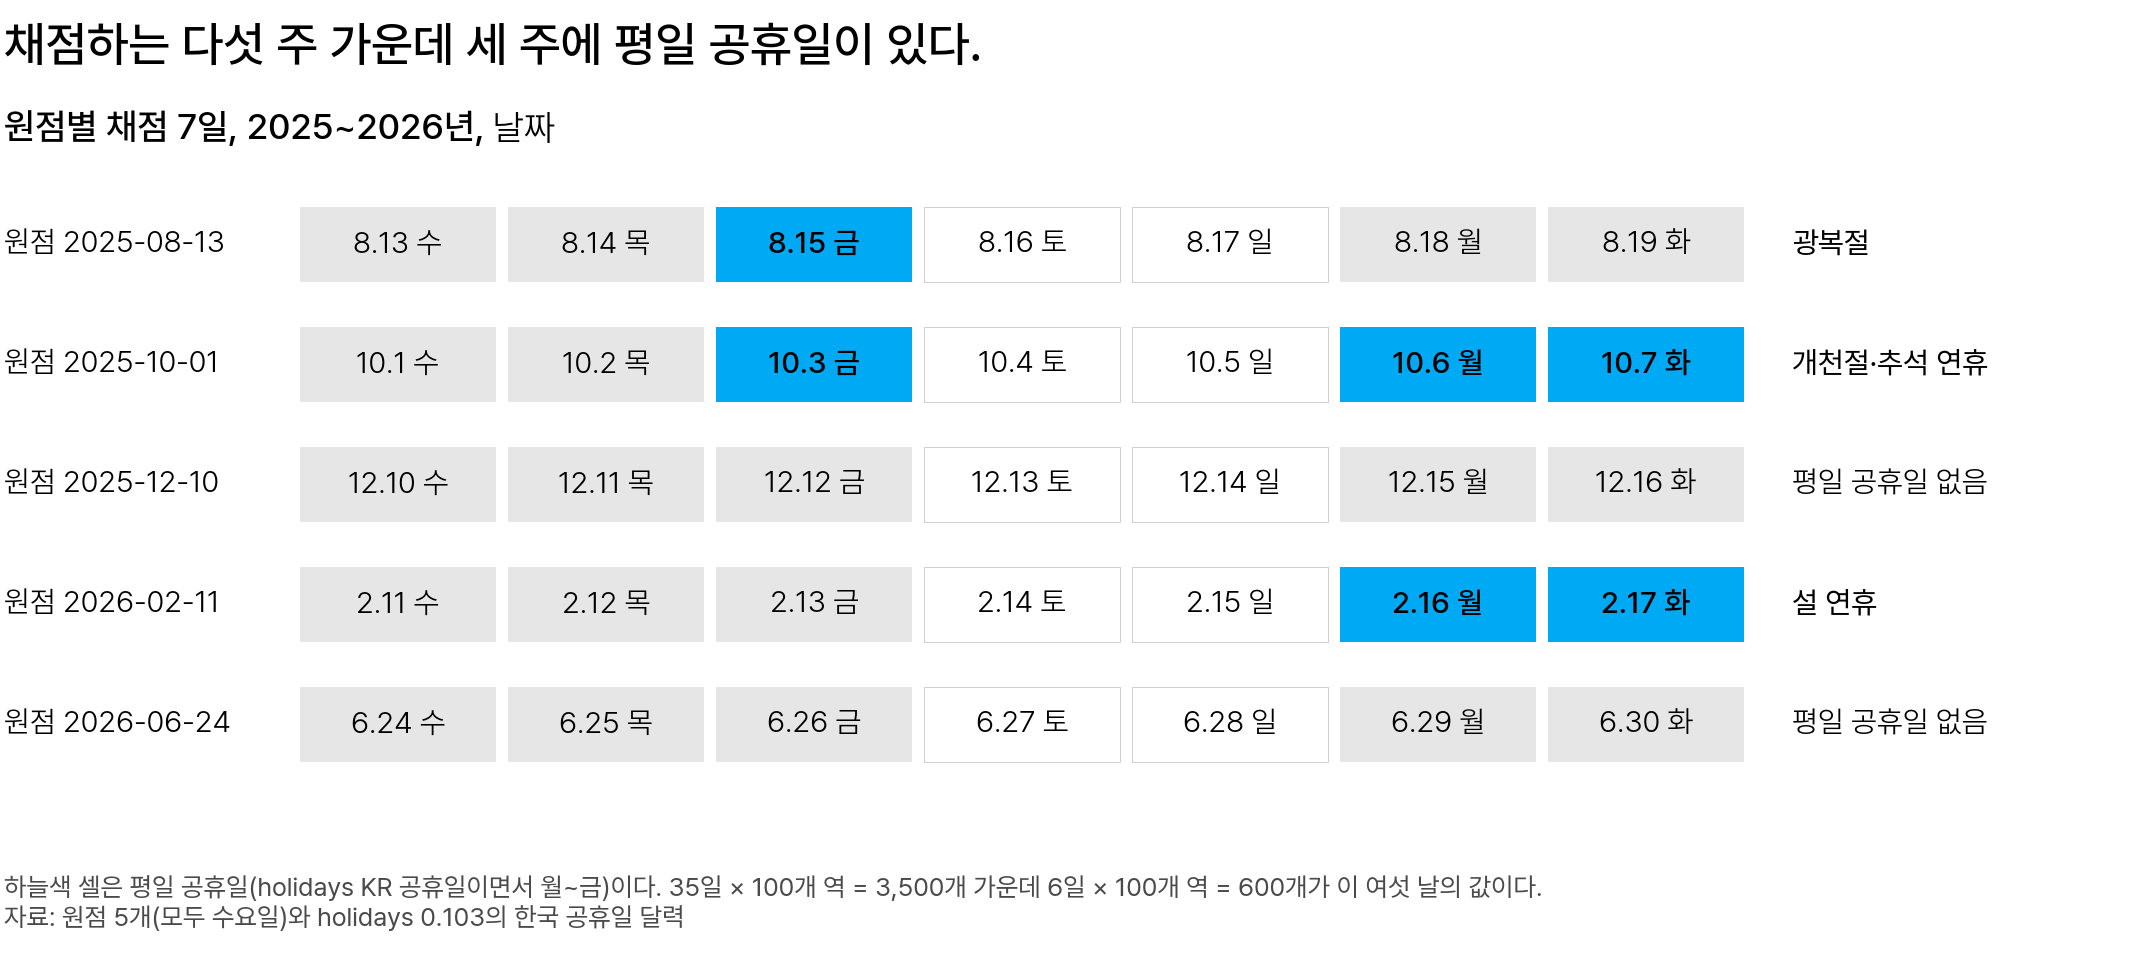

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 채점하는 다섯 주. 한 행이 원점 하나의 채점 7일(수～화)이고, 회색 셀은 평일, 흰 셀은 주말, 하늘색 셀은 평일 공휴일이다. 오른쪽 글자는 그 주의 공휴일 이름이다. 공휴일은 파이썬 라이브러리 holidays 0.103 버전의 한국 공휴일 달력을 따른다</em></p>

예측 원점은 수요일 5개이고, 모델은 원점마다 원점 전날까지의 자료로 새로 학습합니다.

하늘색 셀을 원점 차례로 세면 1 + 3 + 0 + 2 + 0 = 6일입니다.

평일 공휴일이 없는 원점은 2025-12-10 과 2026-06-24 입니다.

2015년부터 수요일에 시작하는 7일은 598개입니다. 그 가운데 481개, 곧 80% 에 평일 공휴일이 없어, 더 흔한 공휴일 없는 주의 결과를 먼저 확인합니다.

**원점 5개를 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠 평균합니다.**

> **[문제] 예측 원점 2025-12-10 에서 신경망에 넣는 입력 28일과 채점하는 7일로 맞는 것은?**
>
> 1. 입력 2025-11-13～12-10, 채점 2025-12-10～12-16
> 2. 입력 2025-11-12～12-09, 채점 2025-12-09～12-15
> 3. 입력 2025-11-12～12-09, 채점 2025-12-10～12-16

### 지금 쓰는 직전 7일 평균은 계절 나이브보다 덜 빗나가나 [필수]

덜 빗나가지 않습니다. 공휴일이 있는 주와 없는 주 모두에서 계절 나이브보다 더 빗나갑니다.

| 베이스라인 | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|
| 계절 나이브 | 0.445 | 2.767 |
| 직전 7일 평균 | 1.935 | 3.684 |

같은 채점 규칙으로 방식마다 MASE 를 적는 이런 표를 **평가표**라 부릅니다. 원점 전날 값을 7일 모두에 쓰는 **나이브 기법(naive method)** 은 요일 차이를 반영하지 못해 이 표에 적지 않습니다.

표의 값은 역마다 구한 MASE 100개를 평균한 역 단위 MASE 입니다.

가게에서는 0 이던 계절 나이브의 MASE 가, 날마다 조금씩 다른 실제 승차에서는 0.445 입니다.

**계절 나이브가 덜 빗나가므로, 새 모델의 MASE 는 공휴일 없는 두 주의 계절 나이브 0.445 보다 낮아야 합니다.**

<details class="lms-extra"><summary>자세히 — 표의 값을 구한 식과, 계절 나이브의 MASE 가 1 보다 작은 까닭</summary>

「1. 예측 원점과 역 단위 MASE」의 식에 서울 지하철의 계열 수 100 을 대입하면 역 단위 MASE 입니다.

$$
\text{역 단위 MASE} = \frac{1}{100}\sum_{i=1}^{100} \frac{\text{MAE}_i}{Q_i}
$$

- $i$: 역 번호(1～100)
- $\text{MAE}_i$, $Q_i$: 역 $i$ 의 MAE 와 MASE 분모

표의 값은 원점마다 구한 역 단위 MASE 를 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠 평균한 값입니다.

0.445 는 두 원점의 값 0.419 와 0.471 의 평균입니다.

공휴일 없는 주에 계절 나이브의 MASE 가 1 보다 작은 까닭은 이렇습니다.

가게 예에서도 $Q$ 를 구할 때 더한 80 + 80 = 160명은 휴일과 그 1주일 뒤의 이틀에서 나왔습니다.

그날이나 1주일 전이 공휴일인 날은 1주일 전 값이 크게 빗나가 $Q_i$ 를 키웁니다.

그래서 공휴일이 없는 7일에는 계절 나이브의 오차가 $Q_i$ 보다 작습니다.

$Q_i$ 는 2015년부터 날마다 구한 $|y_{i,t} - y_{i,t-7}|$ 의 평균입니다.

차이를 구한 날의 수를 $n$, 그 차이를 모두 더한 값을 $S$ 라 두면 다음과 같습니다.

$$
Q_i = \frac{S}{n}
$$

원점 2025-12-10 에서는 $n$ 일의 9.4% 가 그날이나 1주일 전이 공휴일인 날입니다.

이 비율은 달력으로 정해져 100개 역에서 같습니다.

이 날들이 $S$ 에서 차지하는 비율은 역마다 조금 다르고, 100개 역을 모두 더하면 51.3% 입니다.

여기서는 100개 역을 더한 비율 51.3% 를 모든 역에 쓰는 근사로 셈합니다.

나머지 날의 비율을 날 수와 차이의 합에서 따로 구합니다.

날 수에서는 $1 - 0.094 = 0.906$ 이라, 나머지 날은 $0.906\,n$ 일입니다.

차이의 합에서는 $1 - 0.513 = 0.487$ 이라, 나머지 날의 차이를 더하면 $0.487\,S$ 입니다.

그래서 나머지 날만의 평균은 다음과 같습니다.

$$
\text{나머지 날 평균} = \frac{0.487\,S}{0.906\,n}
$$

이 평균을 $Q_i = S / n$ 으로 나눕니다.

$$
\frac{\text{나머지 날 평균}}{Q_i} = \frac{0.487\,S \,/\, (0.906\,n)}{S \,/\, n}
$$

분자와 분모에 함께 있는 $S$ 와 $n$ 을 약분하고 나눗셈을 계산합니다.

$$
\frac{0.487\,S \,/\, (0.906\,n)}{S \,/\, n} = \frac{0.487}{0.906} \approx 0.54
$$

공휴일 없는 주의 7일은 모두 나머지 날입니다.

원점 2025-12-10 의 7일에는 계절 나이브가 나머지 날 평균보다도 덜 빗나갔습니다.

역마다 $\text{MAE}_i$ 를 나머지 날 평균으로 나누면 100개 역 평균 0.776 입니다.

$\text{MASE}_i$ 의 분자와 분모에 같은 나머지 날 평균을 곱하고 나누면, 두 비율의 곱으로 적을 수 있습니다.

$$
\text{MASE}_i = \frac{\text{MAE}_i}{Q_i} = \frac{\text{MAE}_i}{\text{나머지 날 평균}} \times \frac{\text{나머지 날 평균}}{Q_i}
$$

두 비율을 대입하면 0.776 × 0.54 ≈ 0.42 로, 위의 0.419 와 맞습니다.

</details>

### 같은 1,000명 오차는 잠실과 구로에서 같은 크기인가 [선택]

같지 않습니다. 구로의 MASE 가 잠실의 4.6배입니다.

| 역 | $Q_i$ | 7일 내내 1,000명씩 빗나갈 때의 MASE |
|---|---:|---:|
| 2호선 잠실 | 6,405.5명 | 1,000 ÷ 6,405.5 = 0.156 |
| 경부선 구로 | 1,380.8명 | 1,000 ÷ 1,380.8 = 0.724 |
| 두 값의 비 | | 0.724 ÷ 0.156 ≈ 4.6배 |

$Q_i$ 는 원점 2026-06-24 의 값이고, 2015년부터 원점 전날까지 계절 나이브가 그 역에서 빗나간 크기의 평균입니다.

**같은 1,000명도 역마다 $Q_i$ 가 달라 MASE 는 4.6배 차이가 납니다.**

<details class="lms-extra"><summary>자세히 — MASE 를 명 수로 바꾸면, 100개 역을 더해 채점하면</summary>

MASE 에 그 역의 $Q_i$ 를 곱하면 하루 평균 몇 명 빗나갔는지가 나옵니다.

잠실에서 MASE 가 0.5 라면 하루 평균 6,405.5 × 0.5 ≈ 3,203명 빗나갔다는 뜻입니다.

100개 역 승차를 더한 계열 하나로 채점하면 역끼리 반대로 빗나간 오차가 지워집니다.

원점 2025-12-10 에서 이 계열을 계절 나이브로 예측해 채점해 봅니다.

이 계열의 7일 오차 크기를 더한 값은, 역마다 구한 오차 크기를 모두 더한 값의 0.666배입니다.

역을 더하는 동안 오차의 3분의 1이 지워진 것입니다.

그래서 오차와 $Q_i$ 는 역마다 구합니다.

</details>

### 원점 2026-06-24 에 MLP 는 무엇을 입력받나 [선택]

역마다 원점 전 28일을 입력받아 7일을 한 번에 냅니다.

| 역 | 입력 28일: 5/27 수～6/23 화(천 명) | 출력 7일: 6/24 수～6/30 화(천 명, 채점) |
|---|---|---|
| 2호선 강남 | 90.6 · 93.0 · 96.9 · … · 90.9 · 94.1 | 94.3 · 94.1 · 98.5 · 67.6 · 40.2 · 89.9 · 92.1 |
| 2호선 잠실 | 79.7 · 83.2 · 92.1 · … · 80.1 · 84.6 | 85.2 · 84.0 · 92.7 · 85.5 · 60.9 · 79.6 · 82.0 |
| 경부선 구로 | 18.9 · 19.3 · 19.1 · … · 18.3 · 18.7 | 18.8 · 18.4 · 19.1 · 15.2 · 11.4 · 18.1 · 18.4 |

원점의 윈도는 역마다 하나라 100행이고, 입력은 앞 3일과 끝 2일만 적었습니다.

원점 전날까지의 4,192일을 같은 길이로 자르면 윈도 수는 아래와 같습니다.

$$
4{,}192 - 28 - 7 + 1 = 4{,}158, \qquad 4{,}158 \times 100 = 415{,}800
$$

한 역의 4,158개와 100개 역의 415,800개가 가게 예의 15개와 30개에 해당합니다.

**같은 모델 하나가 역마다 그 역의 28일을 입력받아 7일을 냅니다.**

<details class="lms-extra"><summary>자세히 — 한 역의 윈도가 4,158개인 셈</summary>

강남 한 역의 윈도 개수는 「2. 윈도 표」의 식에 대입하면 다음과 같습니다.

$$
T - L - H + 1 = 4{,}192 - 28 - 7 + 1 = 4{,}158
$$

- $T$: 자를 구간의 길이, 원점 전날 6월 23일까지의 4,192일(100개 역 표의 4,199일 − 채점 7일)
- $L$: 입력 길이 28일
- $H$: 출력 길이 7일

첫 윈도와 마지막 윈도의 날짜는 이렇습니다.

| 역 | 윈도 번호 | 입력 28일 | 출력 7일 |
|---|---:|---|---|
| 2호선 강남 | 1 | 2015-01-01～01-28 | 01-29～02-04 |
| 2호선 강남 | ⋮ | ⋮ | ⋮ |
| 2호선 강남 | 4,158 | 2026-05-20～06-16 | 06-17～06-23 |

표의 마지막 윈도가 4,158번째입니다.

입력 2026-05-20～06-16 에 출력 06-17～06-23 이라, 출력 끝날이 원점 전날입니다.

100개 역은 날짜가 같아 역마다 4,158개씩입니다.

</details>

### [직접 해보기] 역 경계와 윈도 [선택]

역마다 날짜별 값을 역 순서로 이어 적은 표가 **롱 포맷(long format)** 표입니다. 위젯에서는 「긴 표」라 부릅니다.

이 표를 역 구분 없이 자르면, 역이 바뀌는 곳의 윈도에 두 역 값이 섞입니다. 위젯은 강남 마지막 49일과 잠실 처음 49일이 맞닿은 곳을 보여 줍니다.

1. **해 보기.** `역 구분 없이 자르기` 탭에서 `윈도 위치` 를 두 역의 경계 쪽으로 움직이거나 `하루 밀기` 를 눌러 봅니다.
2. **관찰.** 경계를 넘는 윈도에서는 다른 역 값의 막대와 셀이 짙은 회색으로 바뀌고, `경계를 넘는가` 에 섞인 날수가 문장으로 나옵니다.
3. **확인 질문.** `역마다 자르기` 탭으로 바꾸면 윈도 개수는 몇 개가 되고, 역 구분 없이 자를 때보다 몇 개 줄어들까요?

In [ ]:
# 인터랙티브 위젯 — 셀을 실행하면 나타납니다 (인터넷 연결 필요)
# 아래가 잘려 보이면 height 값을 키우세요.
from IPython.display import IFrame
IFrame("https://aic-data.aiffel.io/api/widget-file/deep-time-series/window-lab.html", width=980, height=520)

<details class="lms-answer"><summary>답 확인 — 역마다 자를 때 줄어드는 윈도의 개수</summary>

역 구분 없이 자르면 98행 표에서 윈도가 $98 - 28 - 7 + 1 = 64$ 개입니다. 역마다 자르면 한 역 49일에서 $49 - 28 - 7 + 1 = 15$ 개라서 두 역 30개입니다.

줄어든 34개가 경계를 넘던 윈도입니다. 출력 7일이 모두 잠실인데 입력에 강남 날이 있는 윈도 28개와, 출력이 두 역에 걸친 윈도 6개를 더한 수입니다.

</details>

**윈도는 역마다 따로 자른 뒤 한 표로 합쳐야, 한 윈도에 두 역 값이 함께 들어가지 않습니다.**

### 100개 역의 요일 모양은 얼마나 비슷한가 [선택]

100개 역 가운데 96개 역은 일요일 승차가 평일 어느 요일보다 적습니다.

| 값 | 수 | 어디서 온 수인가 |
|---|---:|---|
| 일요일 승차가 평일 어느 요일보다 적은 역 | 96개 | 100개 역 가운데, 원점 2026-06-24 전 1년 |
| 일요일 승차 ÷ 평일 평균이 가장 작은 역 | 0.23배 | 7호선 가산디지털단지, 같은 1년 |
| 일요일 승차 ÷ 평일 평균이 가장 큰 역 | 1.07배 | 경부선 용산, 같은 1년 |

모델이 하나여도 가산디지털단지와 용산의 예측은 다릅니다. 역마다 그 역의 28일을 입력받기 때문입니다.

글로벌 모델이 로컬 모델보다 덜 빗나가는지는 말할 수 없습니다. 평가표에 로컬 모델이 없기 때문입니다. 정확한 표현은 이렇습니다.

> 100개 역이 요일 모양을 공유해 글로벌 모델 하나로 학습했다. 로컬 모델보다 나은지는 확인하지 못했다.

확인하려면 로컬 모델 100개와 글로벌 모델을 같은 원점 5개에서 같은 역 단위 MASE 로 채점합니다.

**96개 역은 일요일 승차가 평일보다 적어 요일 모양이 비슷하지만, 로컬 모델보다 나은지는 확인하지 못했습니다.**

### 100개 역을 표준화 없이 모으면 큰 역의 비중은 얼마인가 [필수]

가게 둘에서는 큰 가게가 제곱의 합에서 92% 를 차지했습니다.

100개 역에서는 승차가 많은 10개 역의 비중을 구합니다.

> **[예측] 표준화 없이 100개 역의 제곱오차를 모으면, 승차 상위 10개 역이 차지하는 비중은 얼마쯤일까요?**
>
> 1. 약 10%
> 2. 약 34%
> 3. 약 90%
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

약 34% 입니다. 역 수로는 10% 인 상위 10개 역이 제곱오차의 33.9% 를 차지합니다.

| 대상 역 | 명 단위 그대로 모을 때 | 역마다 표준화할 때 | 역 수 비율 |
|---|---:|---:|---:|
| 승차 상위 10개 역 | 33.9% | 9.0% | 10% |

모델을 학습하기 전이라, 원점 2026-06-24 전 학습 구간에서 계절 나이브의 제곱오차로 어림했습니다.

표준화하면 상위 10개 역의 비중이 역 수 비율에 가까워집니다.

**100개 역의 윈도는 역마다 표준화한 뒤 한 표로 모읍니다.**

> **[문제] 100개 역의 윈도를 표준화하지 않고 한 모델에 모으면 역마다 오차가 같은 비중으로 들어가므로, 승차 상위 10개 역이 제곱오차에서 차지하는 비중은 10% 안팎이다.**
>
> 1. O (맞다)
> 2. X (틀리다)

### 평균과 표준편차는 어느 날까지의 자료로 구하나 [필수]

역마다 원점 57일 전까지의 자료로 구합니다.

| 구간 | 쓰임 |
|---|---|
| 원점 57일 전까지 | 학습 윈도, 평균과 표준편차 |
| 원점 직전 56일 | 검증 구간(멈출 에폭을 고름) |
| 원점부터 7일 | 채점 |

가게 예에서 쓴 원점 전 자료에서, 검증 구간인 원점 직전 56일을 더 뺐습니다.

검증 구간의 값이 표준화에 쓰이지 않게 하려는 것입니다.

원점 2026-06-24 에서 채점 7일을 더해 다시 구하면 역마다 평균이 조금 바뀌고, 바뀐 비율은 100개 역 평균 0.016% 입니다.

**차이가 0.016% 로 작아도, 채점할 7일의 값으로 구한 평균과 표준편차는 누수입니다.**

> **[문제] 채점 7일을 넣어도 0.016% 인데**
>
> 원점 2026-06-24 의 역별 평균·표준편차를 채점 7일까지 더해 구하면 역마다 평균이 조금 바뀝니다. 그 바뀐 비율을 100개 역에서 평균해도 0.016% 뿐입니다. 그래도 평균·표준편차를 구할 때 채점 7일을 빼는 까닭을 적어 보세요.

### 세 역의 평균과 표준편차는 얼마인가 [선택]

평균은 강남이 구로의 4.6배지만, 표준화하면 세 역의 입력이 비슷한 범위의 수가 됩니다.

| 역 | μ(명) | σ(명) | 입력 28일의 z |
|---|---:|---:|---|
| 2호선 강남 | 85,096.1 | 27,613.8 | 0.20 · 0.29 · 0.43 · … · 0.21 · 0.33 |
| 2호선 잠실 | 77,144.2 | 17,051.9 | 0.15 · 0.36 · 0.88 · … · 0.18 · 0.44 |
| 경부선 구로 | 18,489.5 | 4,618.2 | 0.08 · 0.18 · 0.14 · … · −0.03 · 0.05 |

μ 와 σ 는 2015-01-01 부터 원점 57일 전인 2026-04-28 까지의 자료로 구했습니다.

표의 z 는 28개 가운데 앞 3개와 끝 2개입니다.

강남의 6월 23일 승차 94,098명을 표준화하면 0.326 입니다.

$$
(94{,}098 - 85{,}096.1) \div 27{,}613.8 = 0.326
$$

강남의 표준화 예측이 0.3 이라면, 0.3 × 27,613.8 + 85,096.1 ≈ 93,380명으로 되돌립니다.

**평균이 4.6배 다른 강남과 구로도, 표에 적은 z 는 세 역 모두 −0.03～0.88 사이입니다.**

### 멈출 에폭을 채점 7일로 고르면 MASE 는 얼마나 달라 보이나 [선택]

MASE 가 0.233 낮아 보이지만, 채점할 7일로 멈출 에폭을 고른 누수입니다.

손실을 MSE 로 둔 글로벌 MLP 를 원점 2026-06-24 에서 학습한 결과입니다.

| 멈출 에폭을 고른 구간 | MASE | 읽는 법 |
|---|---:|---|
| 검증 구간(원점 직전 56일) | 0.943 | 평가표에 적는 값 |
| 채점 7일 | 0.710 | 채점할 정답으로 고른 값이라 쓰지 않는다 |

두 값의 차가 0.943 − 0.710 = 0.233 입니다.

**채점 7일로 고른 0.710 은 평가표에 적지 않습니다.**

<details class="lms-extra"><summary>더 깊이 — 같은 원점의 다른 값과, NeuralForecast 에서 같은 설정의 이름</summary>

같은 원점의 계절 나이브는 0.471 입니다.

같은 설정도 시드 0～4 에서 0.553～0.943 으로 달라지고, 0.943 은 시드 0 의 값입니다.

가중치는 정답 7일이 검증 구간 앞에서 끝나는 윈도로만 학습합니다.

역마다 윈도 4,158개 가운데 정답이 검증 구간과 겹치는 56개를 빼, 4,158 − 56 = 4,102개입니다.

실습은 학습 설정을 함수 `fit_global` 하나에 담았습니다.

시계열 신경망 라이브러리 NeuralForecast 에서는 같은 설정을 이런 이름으로 씁니다.

| 하는 일 | 실습의 `fit_global` | NeuralForecast 3.2.1 |
|---|---|---|
| 입력 28일 · 출력 7일 · 은닉층 64 둘 | 함수 안에 고정 | `MLP(h=7, input_size=28, num_layers=2, hidden_size=64)` |
| 계열별 표준화 | 함수 안에서 원점 57일 전까지로 구함 | `NeuralForecast(models, freq="D", local_scaler_type="standard")` |
| 손실 | `loss="mae"` | `loss=MAE()`(MLP 의 기본값) |
| 검증 구간 | 56일 고정 | `nf.fit(df, val_size=56)` |
| 조기 종료 | 5에폭 고정 | `early_stop_patience_steps=5`(5 는 에폭 수가 아니라 검증 횟수다. 검증은 가중치를 `val_check_steps` 번 고칠 때마다 한 번 한다) |
| 시드 | `seed=0` | `random_seed=0`(기본값 1) |

이름을 대응시킨 표이고, 같은 결과가 나오는 설정이라는 뜻은 아닙니다.

이 과정의 MLP 는 학습 윈도 256개를 계산할 때마다 가중치를 한 번 고칩니다.

</details>

### 강남역 개천절이 있는 주에는 MSE 와 MAE 가 어느 값에서 가장 작은가 [필수]

천 명 단위로 적으면 MSE 를 가장 작게 하는 값은 평균 80.42 이고, MAE 를 가장 작게 하는 값은 중앙값 89.7 입니다.

가게의 네 수요일과 같은 계산을 강남역의 2025년 9월 29일～10월 3일 평일 다섯 날로 합니다. 마지막 날이 개천절입니다.

아래 코드를 ▶ 로 실행하면, 다섯 날 모두를 같은 값 $c$ 로 예측할 때 두 손실이 가장 작은 $c$ 를 찾습니다.

In [ ]:
# 다섯 날을 한 값 c 로 예측할 때 MSE·MAE 가 가장 작은 c 찾기
import numpy as np

y = np.array([88.4, 90.4, 89.9, 89.7, 43.7])   # 강남역 2025-09-29 ~ 10-03 승차(천 명)
cs = np.arange(4000, 9501) / 100                # 후보 c: 40.00 ~ 95.00, 0.01 간격

err = y[None, :] - cs[:, None]                  # 행 = 후보 c, 열 = 날
mse = (err ** 2).mean(axis=1)
mae = np.abs(err).mean(axis=1)

print(f"MSE 가 가장 작은 c = {cs[mse.argmin()]:.2f}  (다섯 날 평균 {y.mean():.2f})")
print(f"MAE 가 가장 작은 c = {cs[mae.argmin()]:.2f}  (다섯 날 중앙값 {np.median(y):.2f})")

sq = (y - y.mean()) ** 2                        # 평균에서 계산한 제곱 오차 다섯 개
print(f"개천절 하루가 제곱 오차 합에서 차지하는 비중 = {sq[-1] / sq.sum():.1%}  "
      f"(네 날 {sq[:4].sum():.2f}, 개천절 {sq[-1]:.2f})")

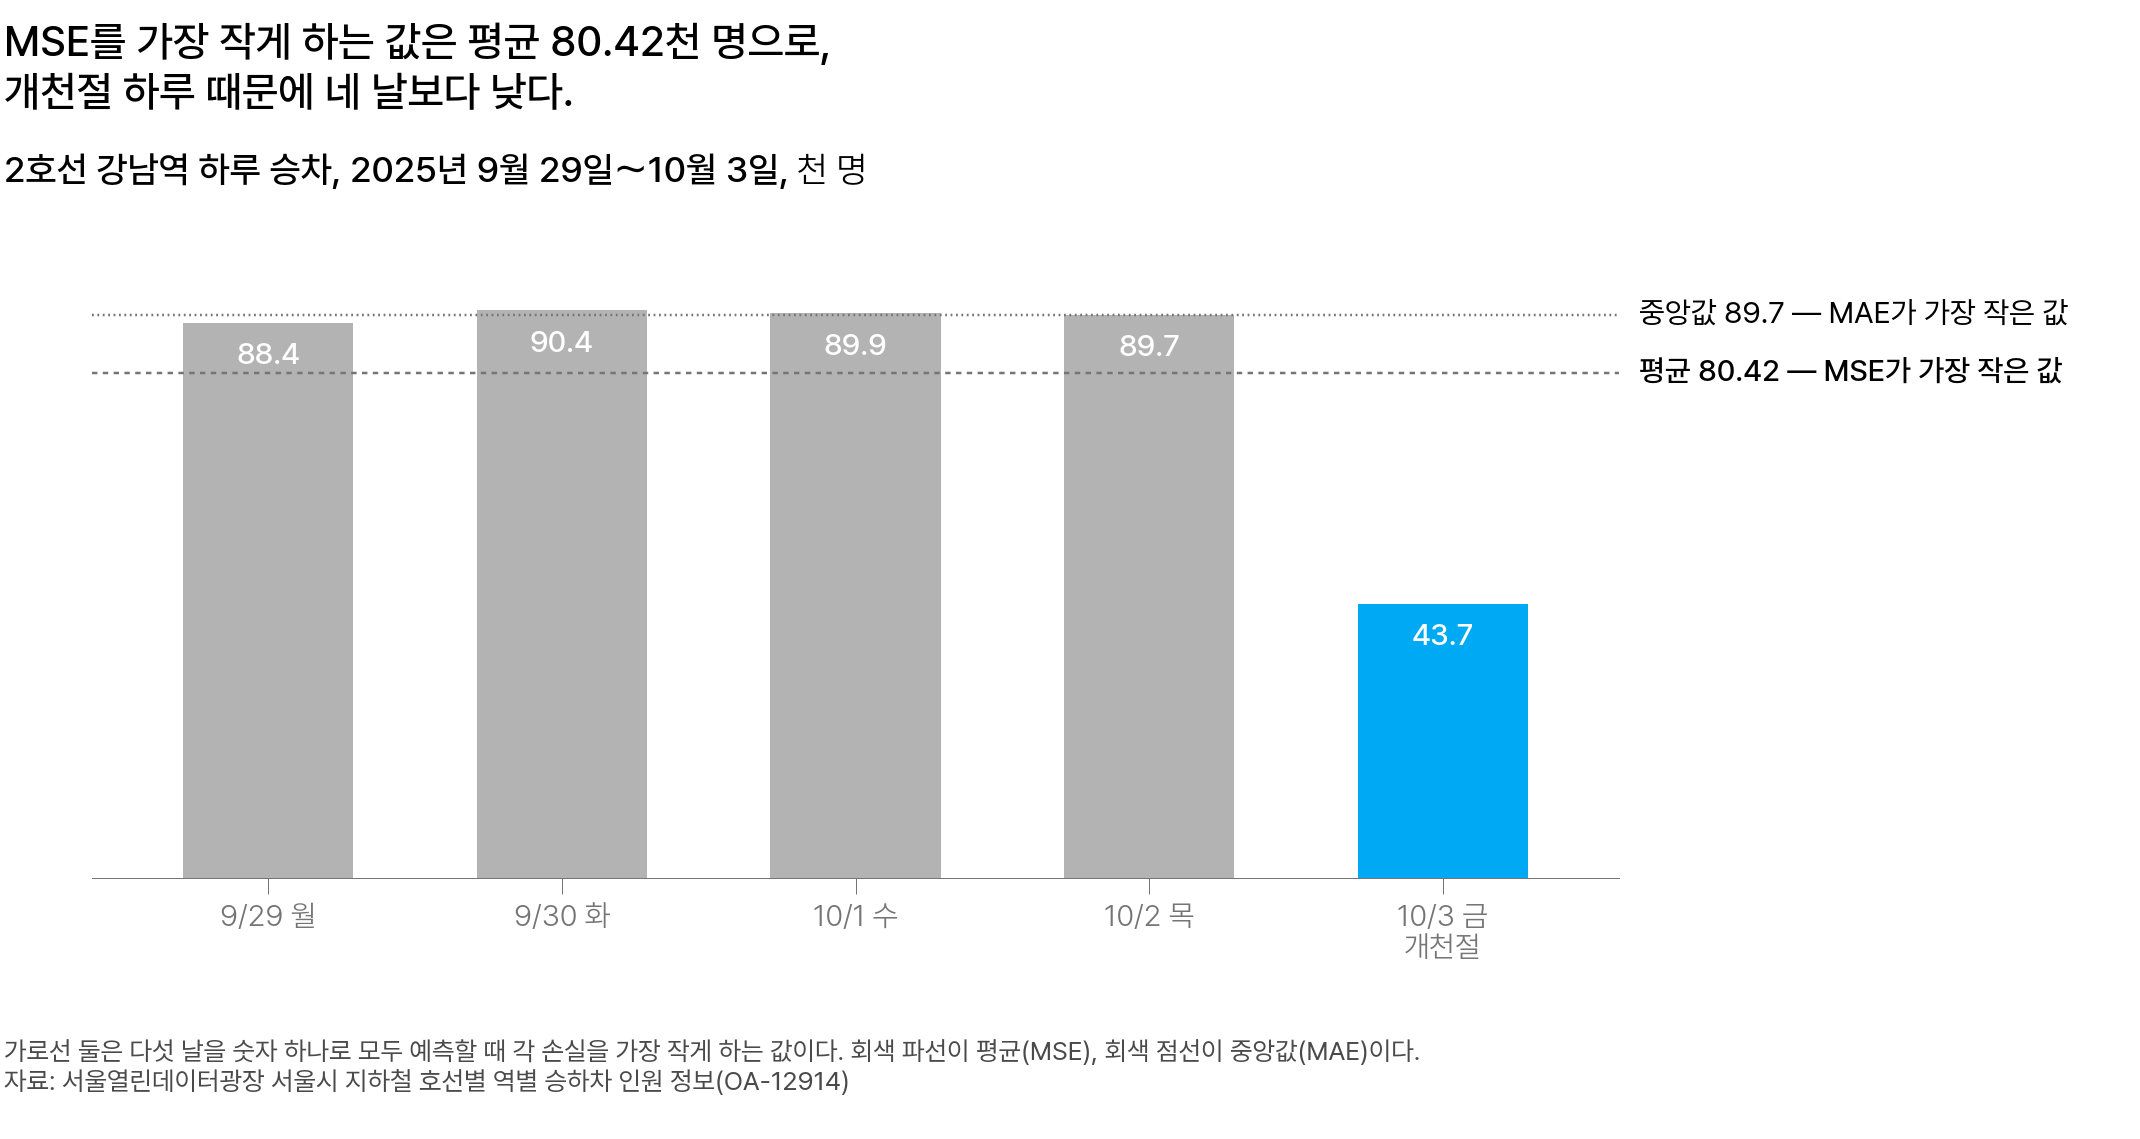

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 2025년 9월 29일 월요일부터 10월 3일 금요일 개천절까지 평일 다섯 날이고, 세로축은 강남역 하루 승차(천 명)다. 두 가로선은 다섯 날을 숫자 하나로 예측할 때 두 손실이 가장 작아지는 값이다. 하늘색 개천절 하루 때문에 MSE 를 가장 작게 하는 값(회색 파선 80.42)은 네 날보다 낮고, MAE 를 가장 작게 하는 값(회색 점선 89.7)은 네 날 높이에 있다</em></p>

평균 80.42 로 예측하면 개천절 하루가 오차 제곱의 합에서 79.9% 를 차지합니다.

가게의 휴일 하루처럼, 드문 하루 때문에 MSE 를 가장 작게 하는 값이 네 날보다 낮아집니다.

**그래서 개천절이 아닌 네 날을 맞히려면 MAE 로 학습합니다.**

<details class="lms-extra"><summary>자세히 — MSE 는 왜 평균에서, MAE 는 왜 중앙값에서 가장 작아지나</summary>

강남역 다섯 날의 승차는 이렇습니다.

| 날 | 9/29 월 | 9/30 화 | 10/1 수 | 10/2 목 | 10/3 금(개천절) |
|---|---:|---:|---:|---:|---:|
| 승차 $y_k$ (천 명) | 88.4 | 90.4 | 89.9 | 89.7 | 43.7 |

다섯 날 모두의 예측값으로 쓰는 숫자 하나를 $c$ 라 하면, 날마다의 오차는 $e_k = y_k - c$ 입니다.

두 후보 $c$ 를 대입하면 이렇습니다.

| 예측값 $c$ | MSE ((천 명)²) | MAE (천 명) |
|---|---:|---:|
| 80.42 (다섯 날의 평균) | 337.53 | 14.69 |
| 89.7 (다섯 날의 중앙값) | 423.64 | 9.64 |

MSE 는 평균 80.42 에서 더 작고, MAE 는 중앙값 89.7 에서 더 작습니다.

실행 셀에서 `y` 배열의 `43.7` 을 `89.0` 으로 바꿔 다시 실행하면 두 값이 89 근처에서 거의 만납니다.

평균 80.42 로 예측할 때 날마다의 오차는 이렇습니다.

| 날 | 9/29 | 9/30 | 10/1 | 10/2 | 10/3(개천절) | 합 |
|---|---:|---:|---:|---:|---:|---:|
| 오차 크기 | 7.98 | 9.98 | 9.48 | 9.28 | 36.72 | 73.44 |
| 제곱 | 63.68 | 99.60 | 89.87 | 86.12 | 1,348.36 | 1,687.63 |

개천절이 아닌 네 날(9/29～10/2)의 값을 더해 개천절 하루와 비교하면 이렇습니다.

| 오차 | 네 날 합 | 개천절 하루 | 개천절 하루의 비중 |
|---|---:|---:|---:|
| 오차 크기 | 7.98 + 9.98 + 9.48 + 9.28 = 36.72 | 36.72 | 50% |
| 오차 제곱 | 63.68 + 99.60 + 89.87 + 86.12 = 339.27 | 1,348.36 | 79.9% |

각 값에서 평균을 뺀 값을 다 더하면 0 이라, 평균보다 큰 날의 오차 합과 작은 날의 오차 합이 늘 같습니다.

이 다섯 날에서는 둘 다 36.72 라, 크기로 세면 개천절 하루가 네 날 합과 같습니다.

제곱으로 세면 1,348.36 ÷ 339.27 ≈ 4.0 이라, 개천절 하루가 네 날 합의 약 4배입니다.

그래서 MSE 를 줄이려면 이 하루의 오차부터 줄여야 합니다.

MSE 의 정의에 예측 $c$ 를 대입합니다.

$$
\text{MSE}(c) = \frac{1}{5}\sum_{k=1}^{5}(y_k - c)^2
$$

$c$ 를 아주 조금 옮길 때 MSE 가 변하는 비율, 곧 $c$ 에 대한 미분을 구합니다. 한 항 $(y_k - c)^2$ 은 $u = y_k - c$ 를 구한 뒤 제곱하는 합성함수라, 합성함수의 미분인 **연쇄 법칙(chain rule)** 을 씁니다. $y_k$ 는 정해진 값이라 $c$ 가 1 늘면 $u$ 는 1 줄어, 안쪽 미분은 $-1$ 입니다.

$$
\begin{aligned}
\text{바깥 미분:}\quad \frac{d}{du}u^2 &= 2u \\
\text{안쪽 미분:}\quad \frac{du}{dc} &= -1 \\
\text{연쇄 법칙(바깥 미분 } \times \text{ 안쪽 미분):}\quad \frac{d}{dc}(y_k - c)^2 &= 2u \times (-1) \\
\text{곱을 계산:}\quad &= -2u \\
u \text{ 에 } y_k - c \text{ 대입:}\quad &= -2(y_k - c)
\end{aligned}
$$

다섯 항을 더해 5 로 나누면 MSE 의 기울기입니다.

$$
\frac{d\,\text{MSE}}{dc} = -\frac{2}{5}\sum_{k=1}^{5}(y_k - c)
$$

MSE 가 가장 작은 $c$ 에서는 이 기울기가 0 입니다. 양변을 $-\tfrac{2}{5}$ 로 나눕니다.

$$
\sum_{k=1}^{5}(y_k - c) = 0
$$

합을 항마다 나눠 적습니다. $c$ 는 다섯 날 모두 같은 값이라 다섯 번 더하면 $5c$ 입니다.

$$
\sum (y_k - c) = \sum y_k - 5c
$$

다섯 날 값의 합 402.1 을 대입합니다.

$$
402.1 - 5c = 0
$$

양변에 $5c$ 를 더하고 5 로 나눕니다. $c = 402.1 \div 5 = 80.42$ 로, 다섯 날의 평균입니다.

MAE 는 미분 대신 $c$ 를 0.1 옮겨 봅니다.

$c = 80.42$ 에서 $c$ 를 0.1 키우면 $c$ 보다 큰 네 날은 오차 크기가 0.1씩 줄고, 개천절 하루만 0.1 늡니다.

오차 크기의 합이 0.4 − 0.1 = 0.3 줄고, MAE 는 0.3 ÷ 5 = 0.06 줄어듭니다.

$c$ 보다 큰 날이 작은 날보다 많은 동안에는 $c$ 를 키울수록 MAE 가 줄어듭니다.

큰 날과 작은 날의 수가 같아지는 곳은 크기 순으로 가운데 값인 89.7 입니다.

그래서 MSE 는 오차의 합이 0 인 평균에서, MAE 는 $c$ 보다 큰 날과 작은 날이 같은 수인 중앙값에서 가장 작습니다.

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Relationship_between_mean_and_median_under_different_skewness.png" alt="오른쪽 꼬리·대칭·왼쪽 꼬리 분포에서 평균과 중앙값의 위치" width="648" height="245"/>
<p align="center"><em>▲ 가로축이 값, 세로축이 그 값이 나오는 빈도다. 세로선은 최빈값(Mode, 가장 자주 나오는 값)·중앙값(Median)·평균(Mean)이다. 왼쪽처럼 오른쪽 꼬리가 길면 평균은 중앙값보다 꼬리 쪽에 있고, 중앙값은 값이 몰린 곳 가까이에 있다 (출처: Wikimedia Commons, Relationship between mean and median under different skewness)</em></p>

| 그림의 영어 | 뜻 |
|---|---|
| Mode | 최빈값. 가장 자주 나오는 값 |
| Median | 중앙값 |
| Mean | 평균 |
| Positive Skew | 오른쪽 꼬리가 긴 분포(왼쪽 그림) |
| Symmetrical Distribution | 좌우가 대칭인 분포(가운데 그림). 세 값이 같은 곳에 있다 |
| Negative Skew | 왼쪽 꼬리가 긴 분포(오른쪽 그림) |

개천절이 있는 주는 오른쪽 그림처럼 왼쪽 꼬리가 긴 경우입니다.

작은 값 43.7 하나 때문에 평균 80.42 는 네 날의 값보다 약 8천～1만 명 낮아집니다.

중앙값은 개천절 값이 43.7 이든 평소 날처럼 89.0 이든 89.7 그대로입니다.

그림은 값이 많은 분포를 그린 것이고, 이 과정의 예는 값이 다섯 개뿐이라 꼬리가 개천절 하루입니다.

</details>

> **[문제] 강남역 개천절이 있는 주의 다섯 날(88.4 · 90.4 · 89.9 · 89.7 · 43.7천 명)을 숫자 하나로 예측할 때, MSE 를 가장 작게 하는 값이 개천절이 아닌 네 날보다 낮은 80.42 로 내려간 이유로 맞는 것은?**
>
> 1. 다섯 날 가운데 공휴일이 하나라서 MSE 가 그날을 한 번 더 더한다
> 2. 오차를 제곱하면 크게 빗나간 개천절 하루가 제곱 오차 합의 79.9% 를 차지해, 그 하루의 오차를 줄이는 쪽으로 값이 낮아진다
> 3. MSE 는 값이 작은 날에 무게를 더 주도록 만든 손실이다

### 손실을 MAE 로 둔 MLP 는 계절 나이브보다 덜 빗나가나 [필수]

구조·조기 종료·시드가 같고 손실만 다른 두 MLP 를 MLP(MSE 손실)·MLP(MAE 손실)이라 부릅니다.

> **[예측] MLP(MAE 손실)은 공휴일 없는 두 주에서 계절 나이브(MASE 0.445)보다 덜 빗나갈까요?**
>
> 1. 덜 빗나간다
> 2. 비슷하다
> 3. 더 빗나간다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

공휴일 없는 두 주에서는 덜 빗나갑니다. MASE 가 0.359 로, 계절 나이브 0.445 보다 낮습니다.

| 방식 | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|
| 계절 나이브 | 0.445 | 2.767 |
| 직전 7일 평균 | 1.935 | 3.684 |
| 글로벌 MLP(MSE 손실) | 0.739 | 2.587 |
| **글로벌 MLP(MAE 손실)** | **0.359** | 2.717 |

두 MLP 의 값은 시드 0 으로 학습한 값입니다.

**공휴일 없는 두 주에서 계절 나이브보다 MASE 가 낮은 방식은 MLP(MAE 손실) 하나입니다.**

<details class="lms-extra"><summary>더 깊이 — 원점 5개 평균과 원점별·시드별 MASE</summary>

원점 5개를 한꺼번에 평균한 MASE 는 이렇습니다.

| 방식 | 원점 5개 평균 |
|---|---:|
| 계절 나이브 | 1.838 |
| 직전 7일 평균 | 2.984 |
| 글로벌 MLP(MSE 손실) | 1.848 |
| 글로벌 MLP(MAE 손실) | 1.774 |

공휴일 있는 주와 없는 주를 함께 평균한 값이라, 공휴일 없는 두 주의 MASE 도, 공휴일 있는 세 주의 MASE 도 아닙니다.

원점별 MASE 는 이렇습니다.

| 방식 | 08-13 | 10-01 | 12-10 | 02-11 | 06-24 |
|---|---:|---:|---:|---:|---:|
| 계절 나이브 | 1.069 | 4.388 | 0.419 | 2.844 | 0.471 |
| 직전 7일 평균 | 2.180 | 4.881 | 1.919 | 3.991 | 1.950 |
| 글로벌 MLP(MSE 손실) | 1.062 | 4.047 | 0.536 | 2.653 | 0.943 |
| 글로벌 MLP(MAE 손실) | 1.067 | 4.322 | 0.326 | 2.762 | 0.393 |

공휴일 없는 두 주와 공휴일 있는 세 주의 평균은 반올림 전 값으로 구해, 이 표의 값으로 평균하면 0.001 다를 수 있습니다.

두 MLP 의 값은 CPU 에서 시드 0 으로 한 번 학습해 구했습니다.

기기가 바뀌면 값이 조금 달라집니다.

Colab T4 GPU 에서는 원점 2026-06-24 의 MLP(MSE 손실) MASE 가 0.897 이었습니다.

시드 0～4 로 다시 학습한 원점 5개 평균은 이렇습니다.

| 방식 | 시드 0 | 시드 1 | 시드 2 | 시드 3 | 시드 4 |
|---|---:|---:|---:|---:|---:|
| 글로벌 MLP(MSE 손실) | 1.848 | 1.779 | 1.821 | 1.806 | 1.771 |
| 글로벌 MLP(MAE 손실) | 1.774 | 1.783 | 1.790 | 1.782 | 1.784 |

계절 나이브는 학습하지 않아 시드와 관계없이 1.838 입니다.

MLP(MAE 손실)은 1.774～1.790 으로 다섯 시드 모두 1.838 보다 낮습니다.

두 MLP 를 비교하면 시드 1·4 에서는 MLP(MSE 손실)이 더 낮아, 원점 5개 평균으로는 어느 쪽이 나은지 말할 수 없습니다.

</details>

### 평가표의 세 방식은 계절 나이브의 몇 배를 빗나가나 [선택]

공휴일 없는 두 주에서 MLP(MAE 손실)만 1배보다 작은 0.81배입니다.

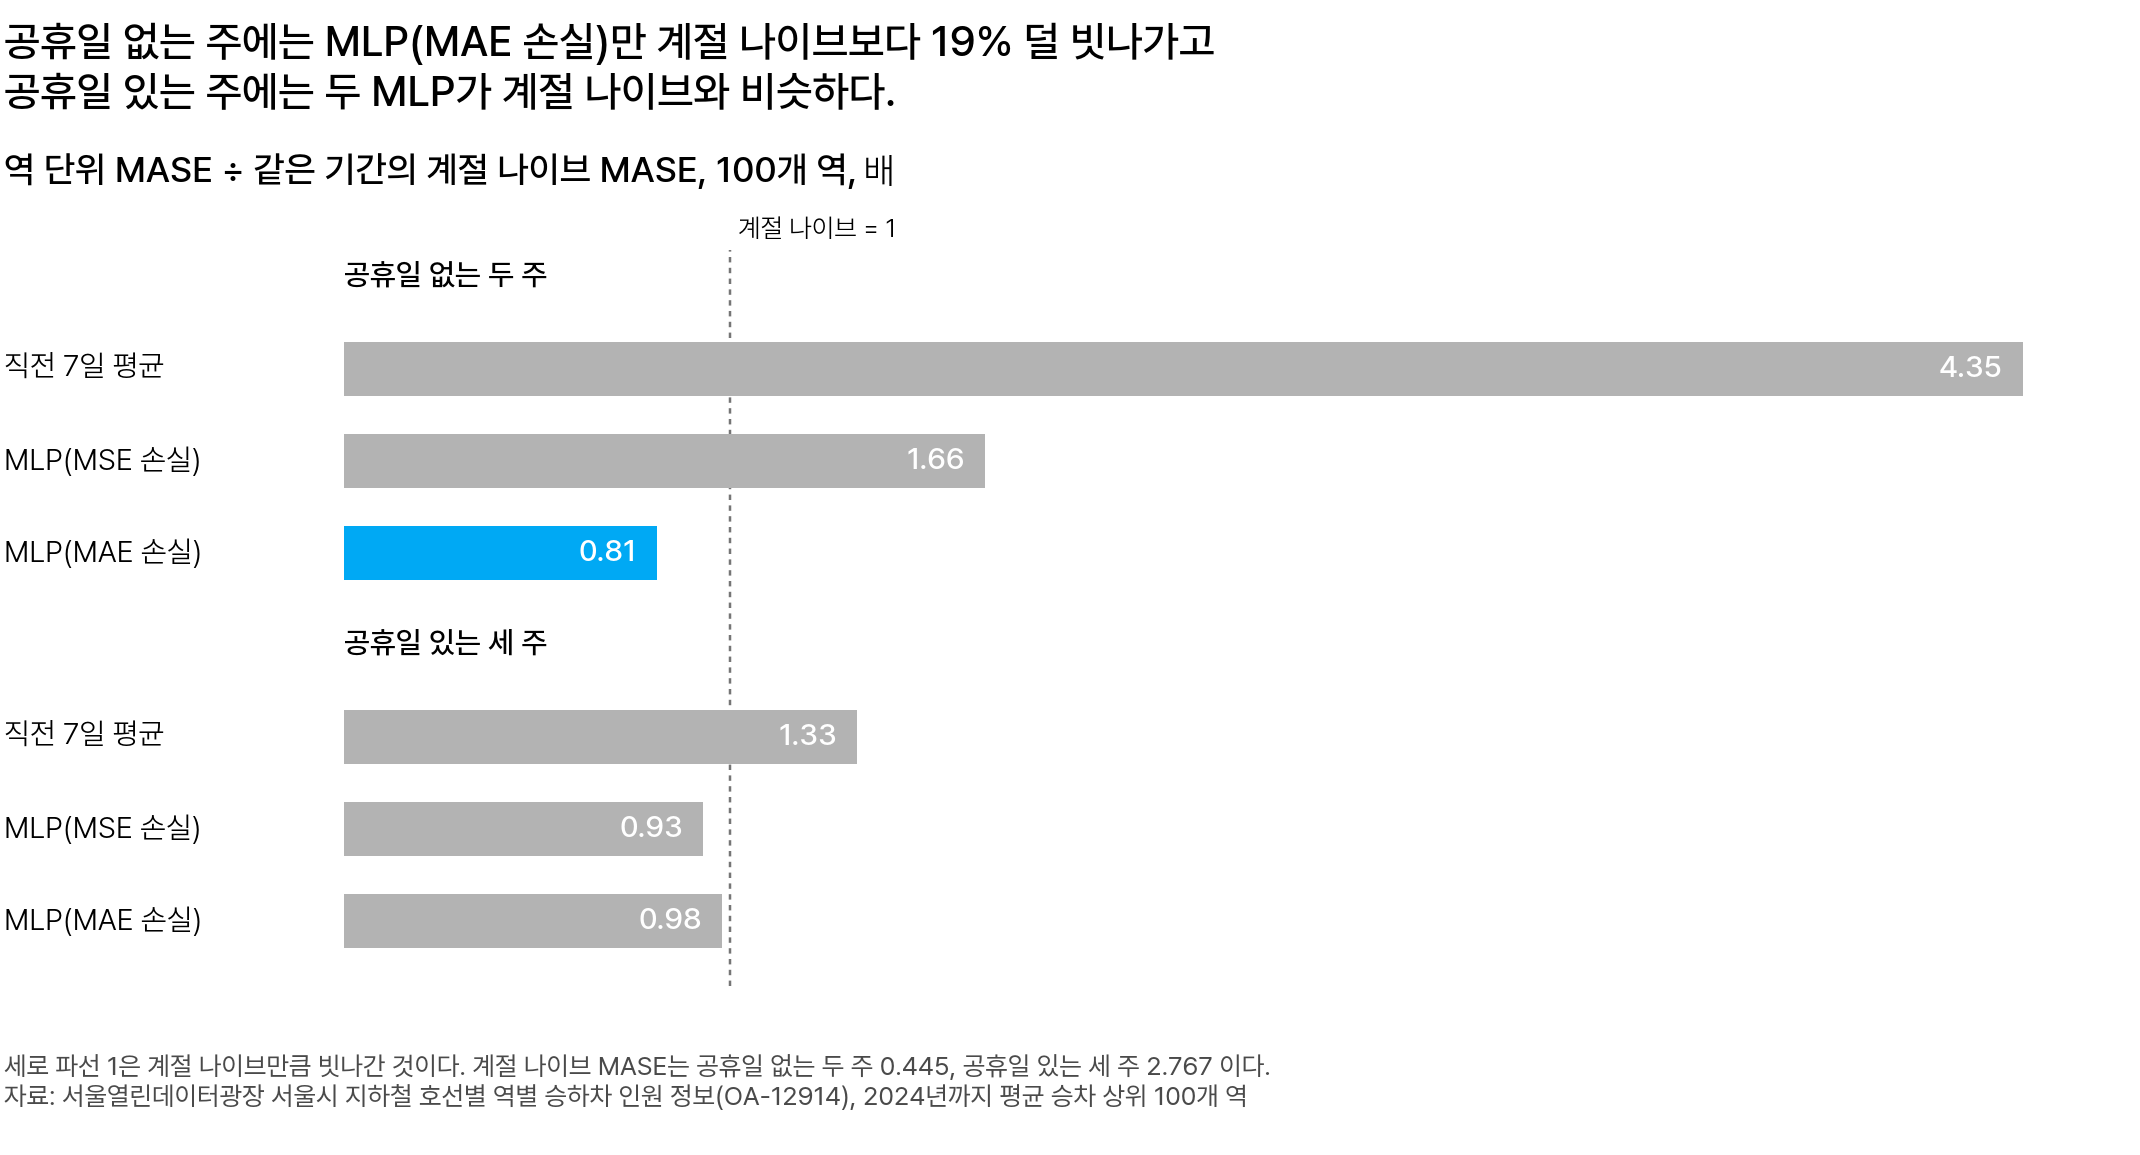

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 평가표 세 방식의 역 단위 MASE 를 같은 기간의 계절 나이브 MASE 로 나눈 배수다. 위는 공휴일 없는 두 주, 아래는 공휴일 있는 세 주다. 회색 세로 파선 1 은 계절 나이브만큼 빗나간 것이고, 막대가 이 선보다 짧을수록 계절 나이브보다 덜 빗나간 것이다. 하늘색 막대가 공휴일 없는 두 주의 MLP(MAE 손실)이다</em></p>

막대에 적힌 수가 이 배수입니다.

MLP(MAE 손실)은 0.359 ÷ 0.445 ≈ 0.81배라, 계절 나이브보다 19% 덜 빗나갑니다.

공휴일 있는 세 주에서는 두 MLP 가 0.93배와 0.98배로, 계절 나이브와 비슷합니다.

**공휴일이 있는 주와 없는 주의 결과가 달라, 모델 선택도 둘로 나눠 정합니다.**

### 공휴일 없는 두 주에는 어느 방식을 쓰나 [필수]

MLP(MAE 손실)을 후보로 올리고, MLP(MSE 손실)은 쓰지 않습니다.

앞에서 정한 대로, 시드 0～4 다섯 번 모두 계절 나이브 0.445 보다 낮을 때만 낫다고 말합니다.

| 방식 | 평가표의 값 | 시드 0～4 의 값 | 읽는 법 |
|---|---:|---|---|
| MLP(MAE 손실) | 0.359 | 0.356～0.372, 다섯 번 모두 0.445 보다 낮다 | 공휴일 없는 주의 후보 |
| MLP(MSE 손실) | 0.739 | 0.571～0.739, 다섯 번 모두 0.445 보다 높다 | 쓰지 않는다 |

**공휴일 없는 주의 후보는 MLP(MAE 손실)이고, 손실을 MSE 로 둔 MLP 는 쓰지 않습니다.**

### MLP(MSE 손실)은 왜 계절 나이브보다 더 빗나가나 [필수]

실제보다 낮게 예측하기 때문입니다.

| 방식 | 실제보다 작은 예측의 비율 |
|---|---:|
| MLP(MSE 손실) | 87.2% |
| MLP(MAE 손실) | 60.5% |
| 계절 나이브 | 52.6% |

공휴일 없는 두 주의 예측 1,400개(100개 역 × 7일 × 2) 가운데 실제보다 작은 예측을 센 값입니다.

실제보다 작게 예측하는 것이 **과소 예측**입니다.

원점 2026-06-24 의 학습 윈도에서 평일 공휴일의 값은 정답 값 개수의 3.8% 입니다.

학습을 마친 MLP(MSE 손실)이 그 윈도에서 낸 손실의 합에서는 평일 공휴일 값이 59.7% 를 차지합니다.

입력이 같던 윈도 10개처럼, 평일 공휴일의 오차를 줄이는 쪽으로 학습하면 공휴일이 아닌 날의 예측이 낮아집니다.

**MSE 로 학습한 MLP 는 공휴일이 아닌 날까지 낮게 예측해, 이 예측대로 인력을 두면 인력이 모자랍니다.**

<details class="lms-extra"><summary>자세히 — 원점 2025-12-10 강남역 앞 5일의 예측</summary>

공휴일 없는 두 주의 예측 표는 100개 역 × 7일 × 2 = 1,400행이고, 한 행은 한 역의 하루입니다.

아래는 원점 2025-12-10 강남의 앞 5일입니다(단위: 명).

| 날짜 | 실제 | 계절 나이브 | MLP(MSE 손실) | MLP(MAE 손실) |
|---|---:|---:|---:|---:|
| 12/10 수 | 91,977 | 89,609 | 88,036 | 93,159 |
| 12/11 목 | 93,905 | 96,709 | 90,601 | 94,540 |
| 12/12 금 | 101,091 | 99,429 | 92,979 | 97,836 |
| 12/13 토 | 71,128 | 67,899 | 65,353 | 67,846 |
| 12/14 일 | 41,209 | 39,487 | 37,758 | 39,995 |

MLP(MSE 손실)은 다섯 날 모두 실제보다 작고, 세 방식 가운데 가장 작습니다.

12월 12일 금요일에는 실제보다 101,091 − 92,979 = 8,112명 적게 예측했습니다.

본문에서 MSE 손실의 59.7% 를 차지한 평일 공휴일 값은, MAE 손실에서는 32.6% 를 차지합니다.

</details>

### 공휴일 있는 세 주에는 어느 방식을 쓰나 [필수]

이 평가표로는 정하지 못합니다. 두 MLP 와 계절 나이브 모두 크게 빗나갑니다.

| 방식 | 공휴일 있는 세 주의 MASE |
|---|---:|
| MLP(MSE 손실) | 2.587 |
| MLP(MAE 손실) | 2.717 |
| 계절 나이브 | 2.767 |

이 오차는 대부분 평일 공휴일 6일에서 나옵니다.

입력 28일 어디에도 다음 주가 공휴일인지가 없기 때문입니다.

그래서 평일 공휴일 6일의 예측 600개는 두 MLP 모두 99.0% 가 실제보다 컸습니다.

MLP(MSE 손실)의 값이 조금 작은 것은 평소 낮게 예측하기 때문이고, 공휴일을 맞혀서가 아닙니다.

**공휴일 여부가 입력에 없어 세 방식 모두 크게 빗나가므로, 어느 방식을 쓸지는 팀 라운드에서 정합니다.**

<details class="lms-extra"><summary>더 깊이 — 공휴일 있는 세 주의 채점 21일을 평일 공휴일과 나머지로 나눈 MASE</summary>

공휴일 있는 세 주의 채점 21일을 평일 공휴일 6일과 나머지 15일로 나눠 평균 MASE 를 구하면 이렇습니다.

| 채점하는 날 | 예측 수 | MLP(MSE 손실) | MLP(MAE 손실) | 계절 나이브 |
|---|---:|---:|---:|---:|
| 평일 공휴일 6일 | 600 | 6.904 | 7.449 | 7.473 |
| 나머지 15일 | 1,500 | 0.860 | 0.824 | 0.885 |

나머지 15일에서는 세 방식 모두 1 보다 작고 MLP(MAE 손실)이 가장 작습니다.

평일 공휴일 6일에서는 세 방식 모두 7 안팎이라, 공휴일 있는 세 주의 평균 2.6～2.8 은 대부분 이 6일에서 나옵니다.

본문 표의 세 방식 모두 $Q_i$ 의 2.6～2.8배를 빗나갑니다.

원점 2025-10-01 의 강남에서 MLP(MAE 손실)은 10월 3일 금요일 개천절을 96,697명으로 예측했습니다.

1주일 전 금요일 값을 옮긴 계절 나이브는 97,311명이고, 실제는 43,721명입니다.

한 역에서 2015년부터 원점 전날까지 4,192일 가운데 평일 공휴일은 160일입니다.

100개 역을 모으면 160일 × 100개 역 = 16,000개 값입니다.

평일 공휴일 사례가 100배가 되는 이점은 공휴일 여부 열을 입력에 더해야 생깁니다.

그 열이 없는 이 MLP 는 이 이점을 얻지 못합니다.

평일 공휴일에 승차가 줄어드는 모양도 100개 역이 비슷합니다.

채점하는 다섯 주의 평일 공휴일 여섯 날에는 100개 역의 값 600개 가운데 592개가 1～4주 전 같은 요일 네 값의 평균보다 적습니다.

그래도 이 MLP 의 입력은 그 역의 28일 승차뿐이고, 역 번호·요일·공휴일 여부를 알리는 열은 없습니다.

평일 공휴일의 정답 값은 학습 윈도에서 지우지 않습니다.

잘못 적힌 값이 아니고, 평일 공휴일은 예측하는 기간에도 있기 때문입니다([fpp3 13.9 「이상치와 결측값 다루기」](https://otexts.com/fpp3/missing-outliers.html)).

</details>

<div class="lms-summary">

**정리**

공휴일 없는 주의 역별 인력 예측 후보는 MLP(MAE 손실)입니다. 공휴일 없는 두 주에서 0.359 로 계절 나이브 0.445 보다 낮고, 시드 0～4 에서도 모두 낮습니다.

**할 일**

- 두 설정은 시드 0～4 모두에서 같은 쪽의 MASE 가 낮은지 확인한 뒤 어느 쪽이 나은지 말합니다

공휴일 있는 주에는 두 MLP 모두 계절 나이브처럼 크게 빗나갑니다.

</div>

> **[문제] MLP(MSE 손실)로 인력을 두면**
>
> MLP(MSE 손실)의 공휴일 없는 두 주 예측 1,400개 가운데 87.2% 가 실제보다 작습니다. 이 예측으로 역별 인력을 두면 어떻게 되는지, 그리고 왜 이렇게 낮게 예측했는지 적어 보세요.

## 7. 정리와 팀 라운드

글로벌 모델로 역별 예측을 낼 때 무엇을 지키고, 다음 주에는 어느 예측을 쓸까요?

### 글로벌 모델로 역별 예측을 낼 때 지킬 것 [선택]

원자료에서 평가표까지 지킬 것은 여덟 가지입니다.

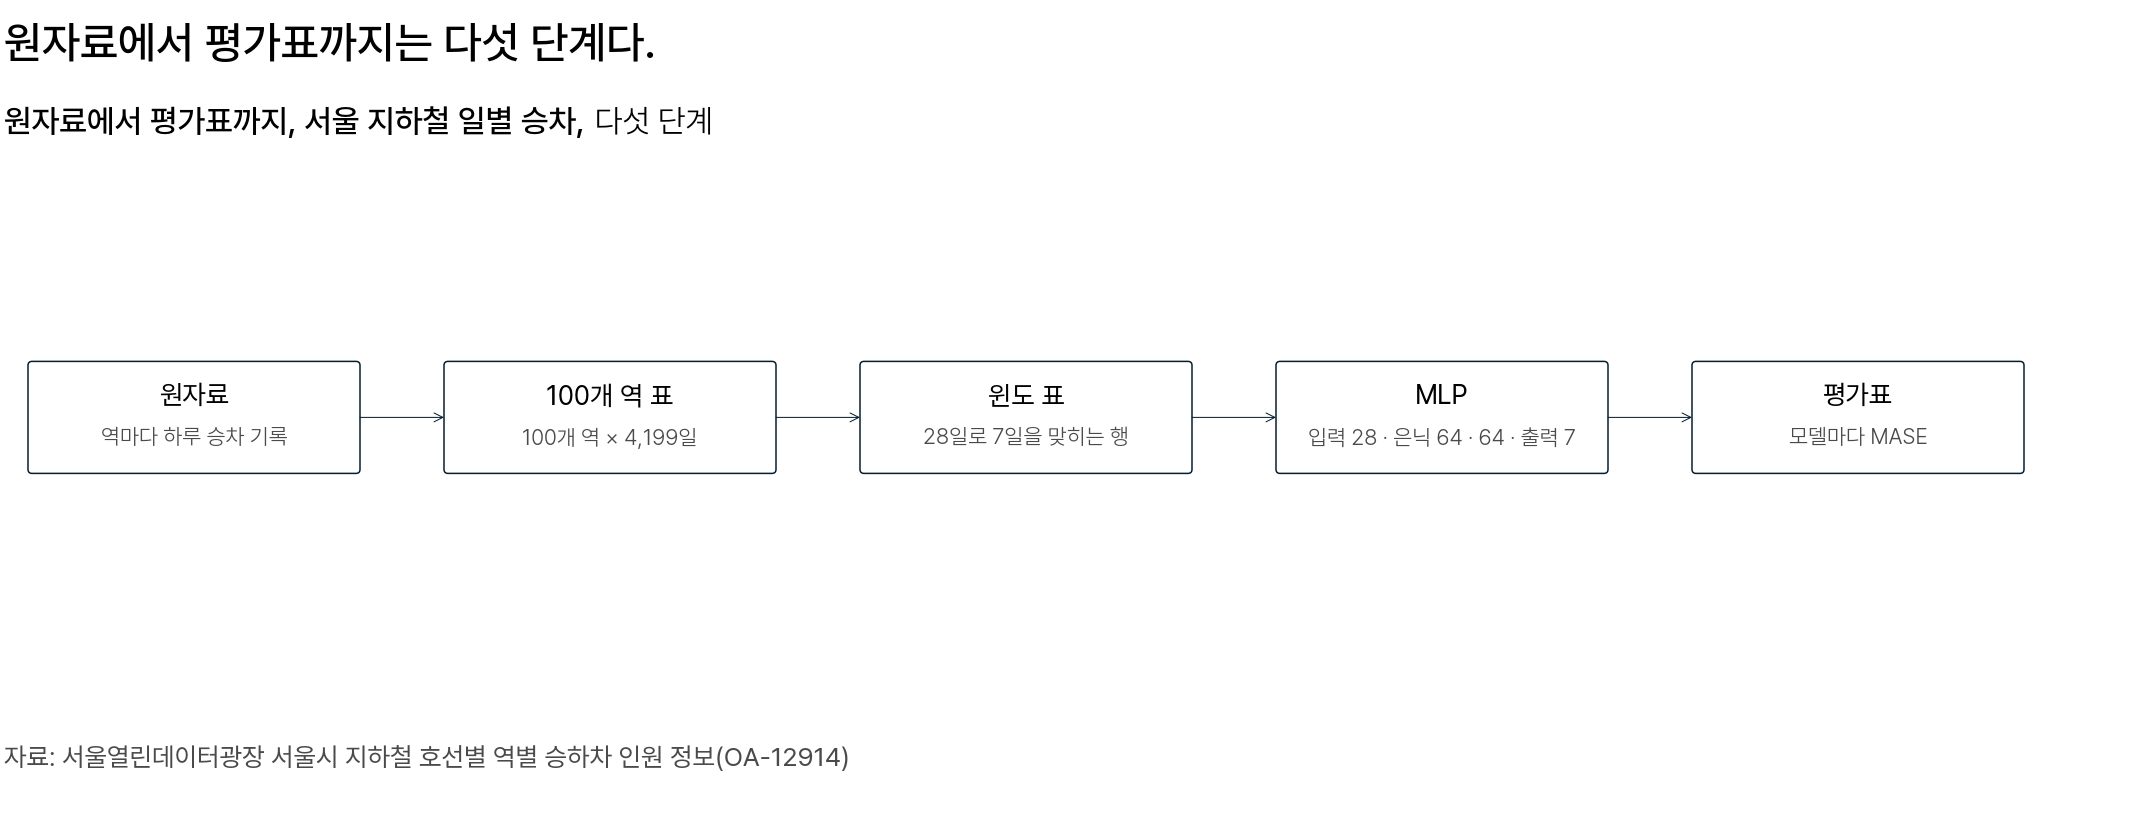

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 원자료에서 평가표까지의 차례. 원자료를 100개 역 표로 모으고, 28일로 다음 7일을 맞히는 윈도 표로 잘라 MLP 에 입력한 뒤, 예측의 MASE 를 평가표에 적는다</em></p>

| 번호 | 단계 | 지킬 것 | 서울 지하철 100개 역에서 |
|---|---|---|---|
| 1 | 모든 단계 | 채점할 7일의 값은 어디에도 쓰지 않음 | 윈도·$Q_i$ 는 원점 전날까지, μ·σ 는 원점 57일 전까지의 자료로 구함 |
| 2 | 100개 역 표 | 드물게 크게 다른 값은 지우지 않음 | 평일 공휴일의 값은 잘못 적힌 값이 아니고, 예측하는 기간에도 평일 공휴일이 있음 |
| 3 | 윈도 표 | 윈도는 역마다 따로 자른 뒤 한 표로 합침 | 윈도 한 행에 두 역 값이 함께 있지 않음 |
| 4 | 윈도 표 | 규모가 다른 역은 역마다 표준화 | 큰 역의 제곱오차 비중이 역 수 비율에 가까워짐 |
| 5 | 윈도 표 | 입력 길이는 계절 주기 7일 이상 | 입력에 1주일 전 같은 요일 값이 있음 |
| 6 | MLP | 손실은 채점 지표에 맞춤 | MASE 로 채점하므로 MAE |
| 7 | 평가표 | 계절 나이브와 같은 원점·채점 단위로 비교함 | 원점 5개, 역 단위 MASE, 공휴일이 있는 주와 없는 주로 나눠 읽음 |
| 8 | 평가표 | 두 설정은 시드 0～4 모두에서 같은 쪽의 MASE 가 낮은지 확인함 | 공휴일 없는 두 주에서 MLP(MAE 손실)만 다섯 번 모두 계절 나이브보다 낮음 |

**채점할 7일을 어디에도 쓰지 않고 계절 나이브와 같은 원점·같은 지표로 비교해야 평가표의 MASE 를 믿을 수 있습니다.**

<div class="lms-summary">

**정리**

100개 역을 신경망 하나로 학습한 글로벌 MLP 는, 손실을 MAE 로 두면 공휴일 없는 주에 계절 나이브보다 덜 빗나갑니다. 로컬 모델보다 나은지는 확인하지 못했습니다.

**할 일**

- 채점할 7일의 값은 어디에도 쓰지 않고, 계절 나이브와 같은 원점·같은 지표로 비교합니다
- 평가표에는 모델마다 공휴일 없는 두 주와 공휴일 있는 세 주의 평균을 따로 적습니다

공휴일 있는 주에 어느 예측을 쓸지는 수업의 팀 라운드에서 정합니다.

</div>

### 수업에서 다룰 질문 [필수]

**아래 질문은 수업에서 팀이 함께 답을 정합니다.** 지금 해설이 열리지 않는 것은 정상입니다.

각자 답과 확신도를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 공휴일 없는 주에 계절 나이브보다 MASE 가 낮은 MLP(MAE 손실)을 다음 주 운영에 넣을까**
>
> 다음 주 역별 인력 배치에 쓸 예측을 정합니다. 글로벌 MLP(MAE 손실)은 공휴일 없는 두 주의 평균 MASE 가 0.359 로 계절 나이브 0.445 보다 낮고, 시드 0～4 에서도 0.356～0.372 로 모두 낮습니다. 공휴일 있는 세 주에서는 2.717 로 계절 나이브 2.767 과 비슷합니다. 원점 5개를 한꺼번에 평균하면(「더 깊이」 상자) 시드 0 에서 1.774 로 네 방식 가운데 가장 낮습니다. 팀 안에서 의견이 셋으로 나뉘었습니다.
> 
> - **관점 A: 모든 주에 MLP(MAE 손실)을 넣는다.** 원점 5개 평균이 네 방식 가운데 가장 낮고, 공휴일 있는 세 주에서도 계절 나이브보다 크게 빗나가지 않는다.
> - **관점 B: 공휴일 없는 주만 MLP(MAE 손실)을 넣고, 평일 공휴일이 있는 주는 운영팀이 정한다.** 공휴일 있는 세 주는 2.717 대 2.767 로 어느 쪽도 쓸 만하지 않고, 평일 공휴일 예측의 99.0% 가 실제보다 컸다.
> - **관점 C: 아직 넣지 않고 계절 나이브를 쓴다.** 공휴일 없는 주가 둘뿐이라, 0.359 가 다음 공휴일 없는 주에도 나온다는 근거가 약하다.
> 
> 자기 입장 하나와 근거 3문장, 그리고 확신도를 정해 오세요.